# EDA
## Разведочный анализ рынка: объём торгов и волатильность

**Автор:** Кравченко Владислав · команда 113

## Специфика анализа

Прежде чем описывать причины исследования той или иной характеристики рыночных торгов, нахожу важным напомнить цель проекта.
Цель проекта — разработать классификатор движения цены финансового инструмента перед выходом из консолидации.
Для достижения этой цели предметом исследования являются:
- формирование кастомного индикатора рыночных консолидаций
- анализ результативности методов машинного обучения (как классических так и нейросетевых) в решении задачи классификации

EDA в данном случае демонстрирует какой набор торговых характеристик поможет приблизиться к цели. И поскольку первым пунктом следует "кастомный индикатор волатильности", то весь EDA анализ вокруг этого и построен. Причина простая, кастомный индикатор волатильности строится на оценке того, насколько сильно обычно «гуляет» цена инструмента, — на **волатильности**, а также на скорости и направлении изменения цены, за что отвечают метрики разброса, ценовых значений, о коих будет сказано далее.

Прежде чем строить как модели, так и индикаторы, нужно хорошо понять сами данные. Вопросы, на которые будут найдены ответы в ходе анализа:

1. **Как мерить волатильность** и чем отличаются два классических способа — ATR и стандартное отклонение (STD).
2. **Когда рынок активен, а когда «спит»:** как меняется объём торгов по месяцам, дням недели и часам внутри дня. От активности рынка зависит, насколько можно доверять движениям цены: в тихие часы диапазон узкий просто потому, что никто не торгует.
3. **Насколько инструменты связаны между собой:** если два инструмента почти всегда движутся вместе, для модели это не два независимых примера, а в каком-то приближении один.
4. **Как волатильность менялась во времени** и как связаны между собой ATR и STD.
5. **Как часто цена делает сильные движения** — уходит от цены открытия дальше своей обычной дневной амплитуды — и в какую сторону закрывается такой день.

Резюмируя: понимая, как меняются характеристики волатильности и какие есть корреляции ли взаимосвязи, можно пролить чуть больше света на вопросы "как написать свой индикатор", что в свою очередь откроет возможность уже детально работать с (главной задачей проекта) разработкой классификатора.

## Какие данные

Рынок США, период **с 15 ноября 2021 по 30 сентября 2026 года** (около 1 225 торговых дней). 2021 и 2026 годы в данных неполные, это учитывается в расчётах.

| Группа | Инструменты |
|---|---|
| Фьючерсы на фондовые индексы (5) | ES — S&P 500, NQ — Nasdaq-100, YM — Dow Jones, RTY — Russell 2000, NKD — японский Nikkei 225 |
| Фьючерсы на металлы (5) | GC — золото, SI — серебро, HG — медь, PL — платина, PA — палладий |
| Акции Health Care (10) | LLY, JNJ, ABBV, UNH, MRK, TMO, AMGN, GILD, ABT, PFE — крупнейшие компании сектора здравоохранения в S&P 500 |
| Акции Materials (10) | LIN, NEM, FCX, ECL, SHW, APD, NUE, CRH, VMC, STLD — крупнейшие компании сектора сырья и материалов |
| Голубые фишки (9) | NVDA, AAPL, MSFT, AMZN, GOOGL, AVGO, META, TSLA, MU — крупнейшие компании S&P 500 по весу (LLY тоже входит в этот список, но показана в Health Care) |

Фьючерсы торгуются почти круглосуточно (с 18:00 до 17:00 следующего дня по Нью-Йорку), акции — в основном с 9:30 до 16:00 по Нью-Йорку, плюс небольшой объём в утренней и вечерней расширенных сессиях. Фьючерс — контракт с датой истечения, поэтому для длинной истории контракты «склеены» в непрерывный ряд, а цены пересчитаны так, чтобы при переходе с одного контракта на следующий не возникало искусственного скачка.

Все графики, кроме корреляций, построены **отдельно для каждой из пяти групп**: инструменты внутри группы похожи друг на друга, а между группами различаются заметно.

In [1]:
import sys
import warnings
from pathlib import Path

# Корень проекта: ищем вверх от папки ноутбука папку, где лежит src/.
# Перед запуском нужны данные (python -m src.data.pipeline) и признаки
# (python -m src.features.build_volatility --member vlad).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "features").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

from src.data.project_config import INTERIM_DIR, PROCESSED_DIR, load_instruments
from src.features.store import load_features

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Оформление графиков
INK, INK2, MUTED, GRID, BASE, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#184f95", "#2a78d6", "#f0efec", "#e34948", "#a02c2c"])
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 2, "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "legend.frameon": False,
})

MEMBER = "vlad"
FULL_YEARS = [2022, 2023, 2024, 2025]
NY = "America/New_York"
MONTHS = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн", "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"]
DAYS = ["Пн", "Вт", "Ср", "Чт", "Пт"]

# Группы инструментов
config = load_instruments()
GROUP = {}
for group in config["team"][MEMBER]["futures"]:
    for item in config["futures"][group]:
        GROUP[item["ticker"]] = group
for group in config["team"][MEMBER]["stocks"]:
    for item in config["stocks"][group]:
        GROUP.setdefault(item["ticker"] if isinstance(item, dict) else item, group)
GROUP_IDS = ["indices", "metals", "health_care", "materials", "blue_chips"]
GROUP_NAME = {"indices": "Фьючерсы на индексы", "metals": "Фьючерсы на металлы", "health_care": "Акции Health Care",
              "materials": "Акции Materials", "blue_chips": "Голубые фишки"}
GROUP_COLOR = dict(zip(GROUP_IDS, [CAT[0], CAT[3], CAT[2], CAT[1], CAT[6]]))
ORDER = [t for g in GROUP_IDS for t in GROUP if GROUP[t] == g]
FUTURES = [t for t in ORDER if GROUP[t] in ("indices", "metals")]
STOCKS = [t for t in ORDER if t not in FUTURES]

def members(group):
    return [t for t in ORDER if GROUP[t] == group]

def heatmap(ax, data, cmap, label, fmt=".2f", center=None, vmin=None, vmax=None, annot_size=8):
    norm = TwoSlopeNorm(vcenter=center, vmin=vmin, vmax=vmax) if center is not None else None
    sns.heatmap(data, cmap=cmap, norm=norm, vmin=None if norm else vmin, vmax=None if norm else vmax,
                annot=True, fmt=fmt, annot_kws={"size": annot_size}, linewidths=0.5, linecolor=SURF,
                cbar_kws={"label": label, "shrink": 0.8}, ax=ax)

for g in GROUP_IDS:
    print(f"{GROUP_NAME[g]} ({len(members(g))}): {', '.join(members(g))}")

Фьючерсы на индексы (5): ES, NQ, YM, RTY, NKD
Фьючерсы на металлы (5): GC, HG, SI, PL, PA
Акции Health Care (10): LLY, JNJ, ABBV, UNH, MRK, TMO, AMGN, GILD, ABT, PFE
Акции Materials (10): LIN, NEM, FCX, ECL, SHW, APD, NUE, CRH, VMC, STLD
Голубые фишки (9): NVDA, AAPL, MSFT, AMZN, GOOGL, AVGO, META, TSLA, MU


In [2]:
# Дневные данные инструментов: цены, ATR, STD и изменение за день.
def load_daily(ticker):
    asset = "futures" if ticker in FUTURES else "stocks"
    d = load_features(asset, ticker, "1day").copy()
    d["trade_date"] = pd.to_datetime(d["trade_date"])
    if asset == "stocks":
        for c in ["open", "high", "low", "close"]:
            d[c] = d[f"split_adj_{c}"]          # цены с поправкой на сплиты
        d["factor"] = 1.0
        d["ret_close"] = d["adj_close"]         # для доходностей — с учётом дивидендов
    else:
        d["ret_close"] = d["close"]             # склеенный ряд сохраняет доходности
    for c in ["open", "high", "low", "close"]:
        d[f"real_{c}"] = d[c] / d["factor"]      # реальные цены дня
    d["ticker"], d["group"] = ticker, GROUP[ticker]
    return d

daily = {t: load_daily(t) for t in ORDER}
panel = pd.concat(daily.values(), ignore_index=True)
print(f"Загружено инструментов: {len(daily)}, строк: {len(panel):,}")

Загружено инструментов: 39, строк: 47,727


## 1. Методы измерения волатильности: ATR и STD

Волатильность — это ответ на вопрос «на сколько обычно двигается цена за день». Мы считаем её двумя классическими способами, оба — по последним **30 торговым дням** (примерно полтора календарных месяца).

**ATR (Average True Range, средний истинный диапазон).** Показатель, который предложил Дж. Уэллс Уайлдер в 1978 году. Для каждого дня берётся «истинный диапазон» — наибольшее из трёх расстояний: от максимума до минимума дня, от максимума дня до вчерашнего закрытия и от минимума дня до вчерашнего закрытия. Так учитываются не только колебания внутри дня, но и разрывы (гэпы) между вчерашним закрытием и сегодняшней торговлей. Затем истинные диапазоны усредняются по 30 дням со сглаживанием Уайлдера: каждый новый день меняет среднее на 1/30, поэтому ATR меняется плавно.

$$TR_t=\max(H_t-L_t,\;|H_t-C_{t-1}|,\;|L_t-C_{t-1}|),\qquad ATR_t=\frac{29\cdot ATR_{t-1}+TR_t}{30}$$

**STD (стандартное отклонение).** Берём изменения цены закрытия от дня ко дню за последние 30 дней и считаем их стандартное отклонение. STD смотрит только на цены закрытия и не видит, как далеко цена уходила внутри дня.

**Три важных решения:**
- **Проценты от цены.** ATR золота измеряется в долларах за унцию, ATR фьючерса на S&P 500 — в пунктах индекса, ATR акции — в долларах за акцию. Сравнивать их напрямую нельзя, поэтому ATR и STD мы переводим в **проценты от цены**. Это же позволяет сравнивать один инструмент в разные годы, когда цена была разной.
- **Только прошлое.** Значение ATR и STD для дня берётся по данным **до предыдущего дня включительно** — то, что известно трейдеру утром до начала торгов. Так будущие модели не смогут «подсмотреть» информацию из будущего. (По тому же методу ведется анализ и в проп-офисах)
- **Реальные цены фьючерсов.** При склейке контрактов цены прошлых лет пересчитываются (у золота, например, примерно на 26%). Мы считаем ATR и STD в реальных ценах тех контрактов, которые торговались в каждый день.

Также посчитано **изменение цены за день** — разницу между закрытием и открытием, в деньгах и в процентах.

In [3]:
level = panel.groupby("ticker")[["atr_30_pct", "std_30_pct"]].median().loc[ORDER]

def volatility_level_report(group):
    tick = members(group)
    data = level.loc[tick].sort_values("atr_30_pct")
    fig, ax = plt.subplots(figsize=(max(6, 0.9 * len(tick) + 2), 3.8))
    x = np.arange(len(data)); w = 0.4
    ax.bar(x - w / 2, data["atr_30_pct"], w - 0.04, color=CAT[0], label="ATR 30")
    ax.bar(x + w / 2, data["std_30_pct"], w - 0.04, color=CAT[1], label="STD 30")
    for i, v in enumerate(data["atr_30_pct"]):
        ax.text(i - w / 2, v + 0.05, f"{v:.1f}", ha="center", fontsize=8, color=INK2)
    ax.set_xticks(x, data.index); ax.set_ylim(0, data["atr_30_pct"].max() * 1.18)
    ax.set_xlabel("Инструмент"); ax.set_ylabel("Медиана за период, % от цены")
    ax.set_title(f"{GROUP_NAME[group]}: типичная дневная волатильность")
    ax.legend(loc="upper left")
    plt.show()
    table = data.rename(columns={"atr_30_pct": "ATR 30, % (медиана)", "std_30_pct": "STD 30, % (медиана)"})
    table["ATR / STD"] = table.iloc[:, 0] / table.iloc[:, 1]
    display(table.T)

### Фьючерсы на фондовые индексы

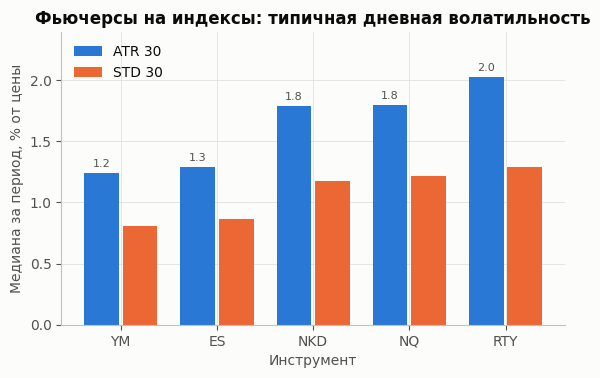

ticker,YM,ES,NKD,NQ,RTY
"ATR 30, % (медиана)",1.24,1.29,1.78,1.80,2.03
"STD 30, % (медиана)",0.81,0.87,1.17,1.22,1.29
ATR / STD,1.54,1.49,1.52,1.48,1.58


In [4]:
volatility_level_report("indices")

### Фьючерсы на металлы

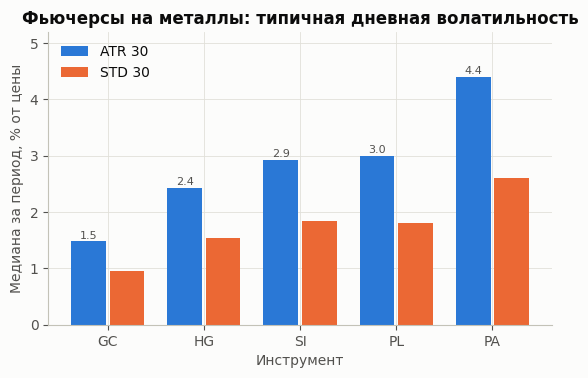

ticker,GC,HG,SI,PL,PA
"ATR 30, % (медиана)",1.48,2.43,2.93,2.99,4.40
"STD 30, % (медиана)",0.96,1.54,1.83,1.81,2.61
ATR / STD,1.54,1.58,1.60,1.66,1.69


In [5]:
volatility_level_report("metals")

### Акции сектора Health Care (здравоохранение)

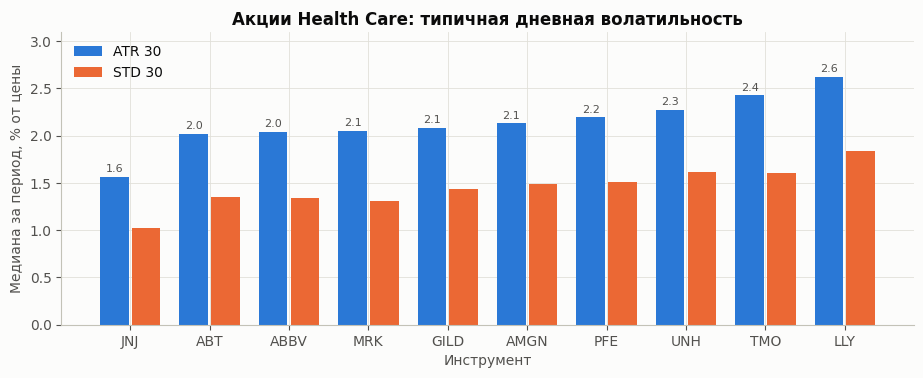

ticker,JNJ,ABT,ABBV,MRK,GILD,AMGN,PFE,UNH,TMO,LLY
"ATR 30, % (медиана)",1.56,2.02,2.04,2.05,2.08,2.13,2.19,2.28,2.43,2.62
"STD 30, % (медиана)",1.03,1.36,1.34,1.31,1.44,1.49,1.51,1.61,1.60,1.83
ATR / STD,1.52,1.49,1.52,1.57,1.45,1.43,1.45,1.41,1.51,1.43


In [6]:
volatility_level_report("health_care")

### Акции сектора Materials (сырьё и материалы)

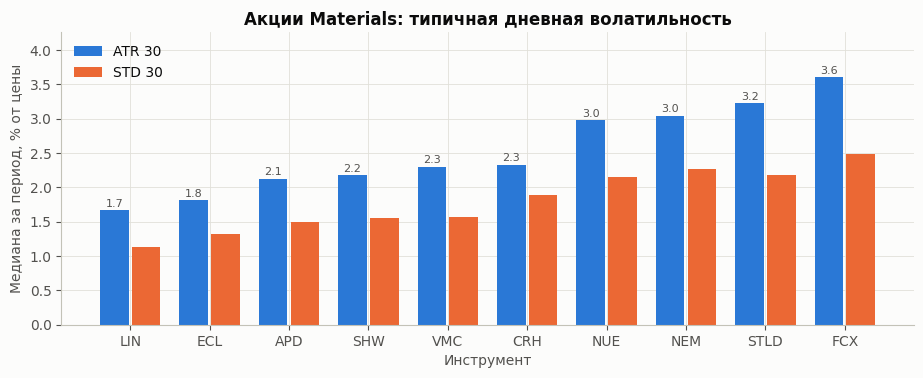

ticker,LIN,ECL,APD,SHW,VMC,CRH,NUE,NEM,STLD,FCX
"ATR 30, % (медиана)",1.66,1.82,2.13,2.18,2.30,2.33,2.98,3.04,3.23,3.61
"STD 30, % (медиана)",1.13,1.32,1.50,1.55,1.57,1.89,2.15,2.27,2.18,2.48
ATR / STD,1.47,1.37,1.42,1.41,1.46,1.24,1.39,1.34,1.48,1.45


In [7]:
volatility_level_report("materials")

### Голубые фишки

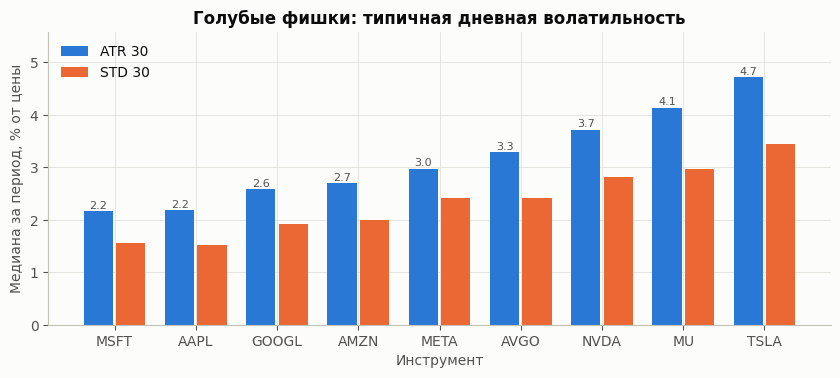

ticker,MSFT,AAPL,GOOGL,AMZN,META,AVGO,NVDA,MU,TSLA
"ATR 30, % (медиана)",2.17,2.19,2.59,2.70,2.97,3.29,3.72,4.14,4.73
"STD 30, % (медиана)",1.56,1.52,1.93,2.00,2.42,2.41,2.81,2.97,3.45
ATR / STD,1.39,1.44,1.34,1.35,1.23,1.37,1.32,1.39,1.37


In [8]:
volatility_level_report("blue_chips")

#### Вывод по разделу 1

- **Уровень волатильности у инструментов различается почти в четыре раза.**
    - Самые спокойные — фьючерсы на Dow Jones (YM, 1.24% от цены в день) и S&P 500 (ES, 1.29%), золото (GC, 1.48%) и акция Johnson & Johnson (JNJ, 1.56%).
    - Самые подвижные — Tesla (TSLA, 4.73%), палладий (PA, 4.40%), Micron (MU, 4.14%), NVIDIA (NVDA, 3.72%) и Freeport-McMoRan (FCX, 3.61%).

  Поэтому задавать один и тот же порог движения в долларах или пунктах для всех инструментов нельзя: для YM движение на 2% — событие, для TSLA — обычный день. Все сравнения дальше ведём в процентах от цены.
- **Внутри групп разброс тоже заметный.**
    - Фьючерсы на индексы: 1.2–2.0%. Малые компании (RTY) и Nasdaq (NQ) подвижнее широкого рынка.
    - Металлы: от спокойного золота (1.5%) до палладия (4.4%).
    - Health Care — самая однородная группа: 1.6–2.6%.
    - Materials: 1.7–3.6%. Металлурги и горнодобытчики подвижнее химических компаний.
    - Голубые фишки: 2.2–4.7%, самая волатильная группа.
- **ATR стабильно в 1.2–1.7 раза больше STD.** У фьючерсов отношение около 1.5–1.7, у акций — 1.2–1.6. ATR измеряет полный дневной размах цены, а STD — только разброс цен закрытия, поэтому ATR всегда больше. Отношение у всех инструментов похожее, значит, оба показателя описывают одно и то же явление, но в разном масштабе.

## 2. Объём торгов по месяцам

**Вопрос.** Есть ли у рынка «сезоны» — месяцы, когда торгуют активнее или спокойнее обычного?

**Как считали.**
- Для каждого дня берём объём торгов. У акций — количество проданных акций за день с поправкой на сплиты. У фьючерсов — суммарный объём двух ближайших контрактов: в дни, когда рынок переходит со старого контракта на новый, объём делится между ними, и если брать только один контракт, получится ложный провал.
- Объёмы разных инструментов отличаются в тысячи раз, поэтому сравниваем не сами объёмы, а **индекс объёма**: средний дневной объём месяца, делённый на средний дневной объём того же года. **1.00** — обычный месяц, **1.20** — на 20% активнее среднего, **0.85** — на 15% тише.
- Сезонность считаем по полным годам 2022–2025. Неполные 2021 и 2026 годы показаны только на карте по годам.

**На графиках для каждой группы:**
- слева — средний индекс объёма по месяцам (насколько каждый месяц в среднем активнее или тише обычного);
- справа — как менялся объём во времени: средний дневной объём каждого месяца относительно среднего за весь период;
- ниже — две тепловые карты: по инструментам и по годам. Красный цвет — месяц активнее среднего, синий — тише.

In [9]:
def daily_volume(ticker):
    if GROUP[ticker] in ("indices", "metals"):
        plan = pd.read_csv(INTERIM_DIR / "futures_plan" / f"{ticker}.csv", parse_dates=["date"])
        return plan.set_index("date")[["front_volume", "next_volume"]].sum(axis=1)
    return daily[ticker].set_index("trade_date")["split_adj_volume"]

vol = pd.concat({t: daily_volume(t) for t in ORDER}, names=["ticker", "date"]).rename("volume").reset_index()
vol["group"] = vol["ticker"].map(GROUP)
vol["year"], vol["month"], vol["weekday"] = vol["date"].dt.year, vol["date"].dt.month, vol["date"].dt.weekday
vol["idx"] = vol["volume"] / vol.groupby(["ticker", "year"])["volume"].transform("mean")
full = vol[vol["year"].isin(FULL_YEARS)]
month_inst = full.groupby(["ticker", "year", "month"])["idx"].mean().groupby(["ticker", "month"]).mean().unstack()

def month_report(group):
    tick = members(group)
    by_month = month_inst.loc[tick].mean()
    v = vol[vol["ticker"].isin(tick)]
    by_year = v.groupby(["ticker", "year", "month"])["idx"].mean().groupby(["year", "month"]).mean().unstack()
    trend = v.assign(period=v["date"].dt.to_period("M")).groupby(["ticker", "period"])["volume"].mean()
    trend = (trend / trend.groupby("ticker").transform("mean")).groupby("period").mean()

    fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 1.3]})
    ax = axes[0]
    colors = [GROUP_COLOR[group] if x >= 1 else BASE for x in by_month]
    ax.bar(range(12), by_month, color=colors, width=0.75)
    ax.axhline(1, color=INK2, lw=1, ls="--")
    for i, x in enumerate(by_month):
        ax.text(i, x + 0.01, f"{x:.2f}", ha="center", fontsize=8, color=INK2)
    ax.set_xticks(range(12), MONTHS); ax.set_ylim(0.6, max(1.25, by_month.max() + 0.08))
    ax.set_xlabel("Месяц"); ax.set_ylabel("Индекс объёма (1 = средний за год)")
    ax.set_title("Средний индекс объёма по месяцам, 2022–2025")
    ax = axes[1]
    ax.plot(trend.index.to_timestamp(), trend.values, color=GROUP_COLOR[group])
    ax.axhline(1, color=INK2, lw=1, ls="--")
    ax.set_xlabel("Дата"); ax.set_ylabel("Объём месяца / средний за период")
    ax.set_title("Объём во времени (среднее по инструментам группы)")
    fig.suptitle(GROUP_NAME[group], x=0.01, ha="left", fontweight="bold", fontsize=13)
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(15, 0.45 * len(tick) + 2.2))
    heatmap(axes[0], month_inst.loc[tick].rename(columns=dict(enumerate(MONTHS, 1))), DIV, "Индекс объёма",
            center=1, vmin=0.6, vmax=1.6)
    axes[0].set_xlabel("Месяц"); axes[0].set_ylabel("Инструмент")
    axes[0].set_title("По инструментам (2022–2025)")
    heatmap(axes[1], by_year.rename(columns=dict(enumerate(MONTHS, 1))), DIV, "Индекс объёма", center=1, vmin=0.6, vmax=1.6)
    axes[1].set_xlabel("Месяц"); axes[1].set_ylabel("Год")
    axes[1].set_title("По годам (2021 и 2026 — неполные)")
    plt.tight_layout(); plt.show()

    s = by_month.rename(index=dict(enumerate(MONTHS, 1)))
    print("Самые активные месяцы:", ", ".join(f"{m} ({x:.2f})" for m, x in s.nlargest(3).items()))
    print("Самые тихие месяцы:   ", ", ".join(f"{m} ({x:.2f})" for m, x in s.nsmallest(3).items()))
    print("Самые активные месяцы по годам:", ", ".join(f"{y}: {MONTHS[m-1]} ({by_year.loc[y, m]:.2f})"
                                                      for y, m in by_year.idxmax(axis=1).items()))

### Фьючерсы на фондовые индексы

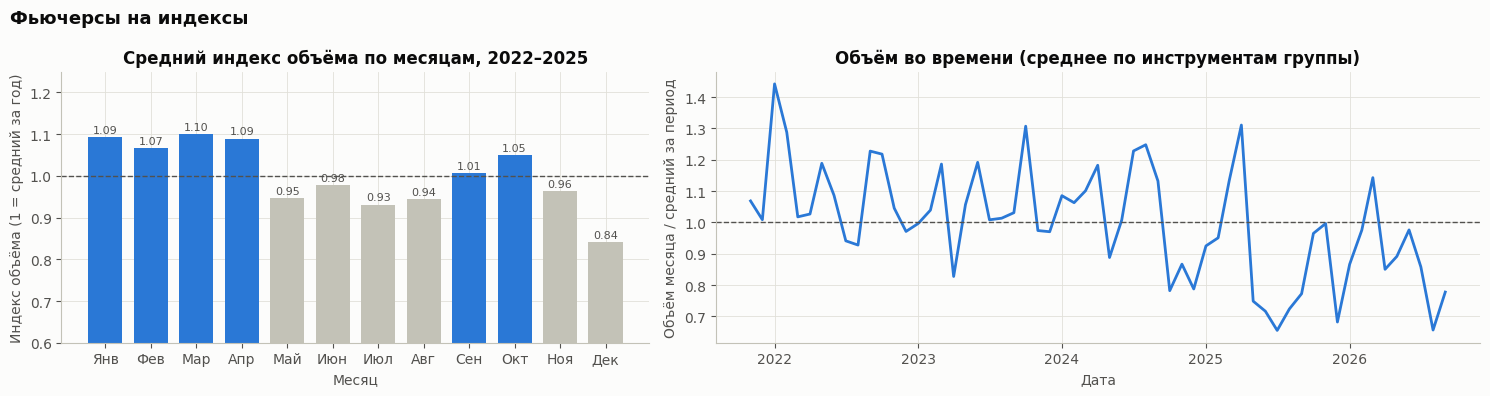

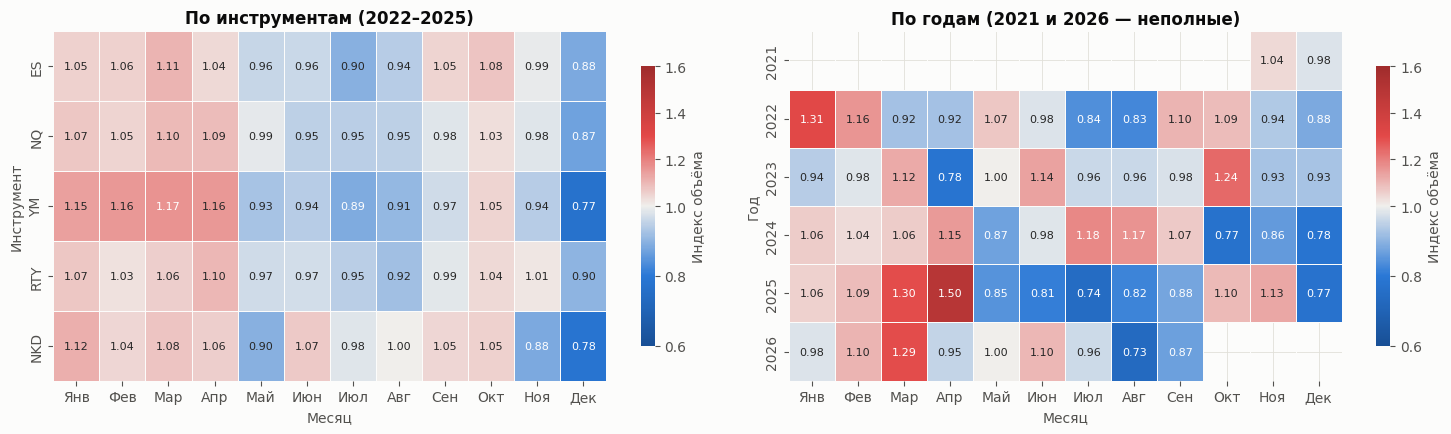

Самые активные месяцы: Мар (1.10), Янв (1.09), Апр (1.09)
Самые тихие месяцы:    Дек (0.84), Июл (0.93), Авг (0.94)
Самые активные месяцы по годам: 2021: Ноя (1.04), 2022: Янв (1.31), 2023: Окт (1.24), 2024: Июл (1.18), 2025: Апр (1.50), 2026: Мар (1.29)


In [10]:
month_report("indices")

### Фьючерсы на металлы

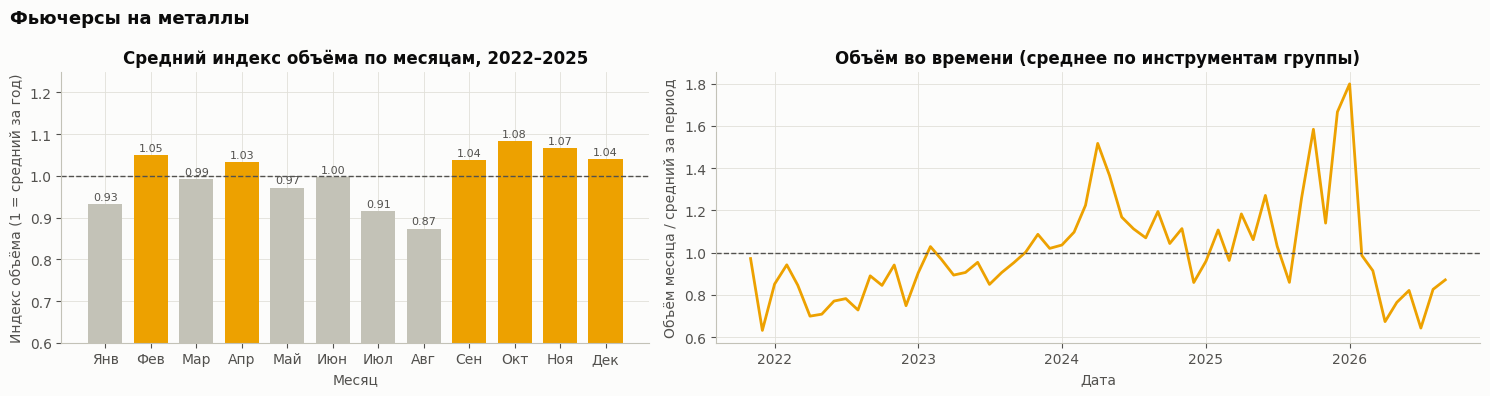

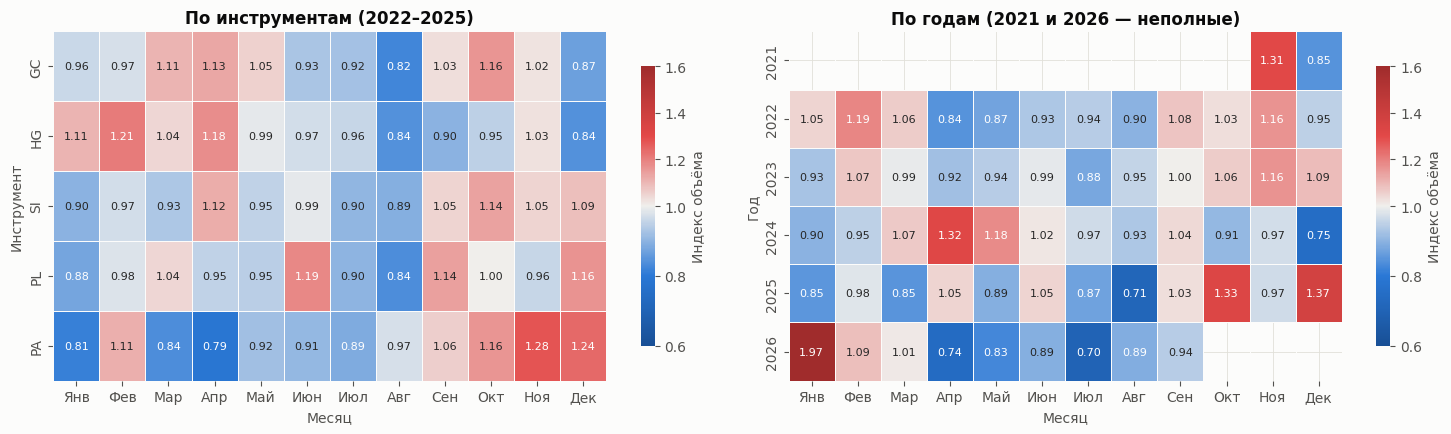

Самые активные месяцы: Окт (1.08), Ноя (1.07), Фев (1.05)
Самые тихие месяцы:    Авг (0.87), Июл (0.91), Янв (0.93)
Самые активные месяцы по годам: 2021: Ноя (1.31), 2022: Фев (1.19), 2023: Ноя (1.16), 2024: Апр (1.32), 2025: Дек (1.37), 2026: Янв (1.97)


In [11]:
month_report("metals")

### Акции сектора Health Care (здравоохранение)

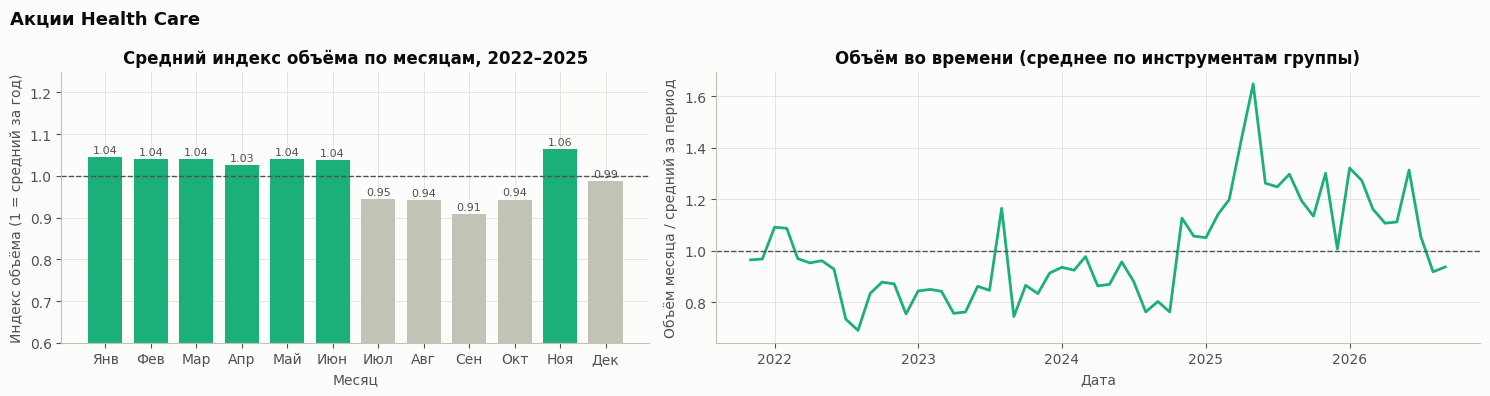

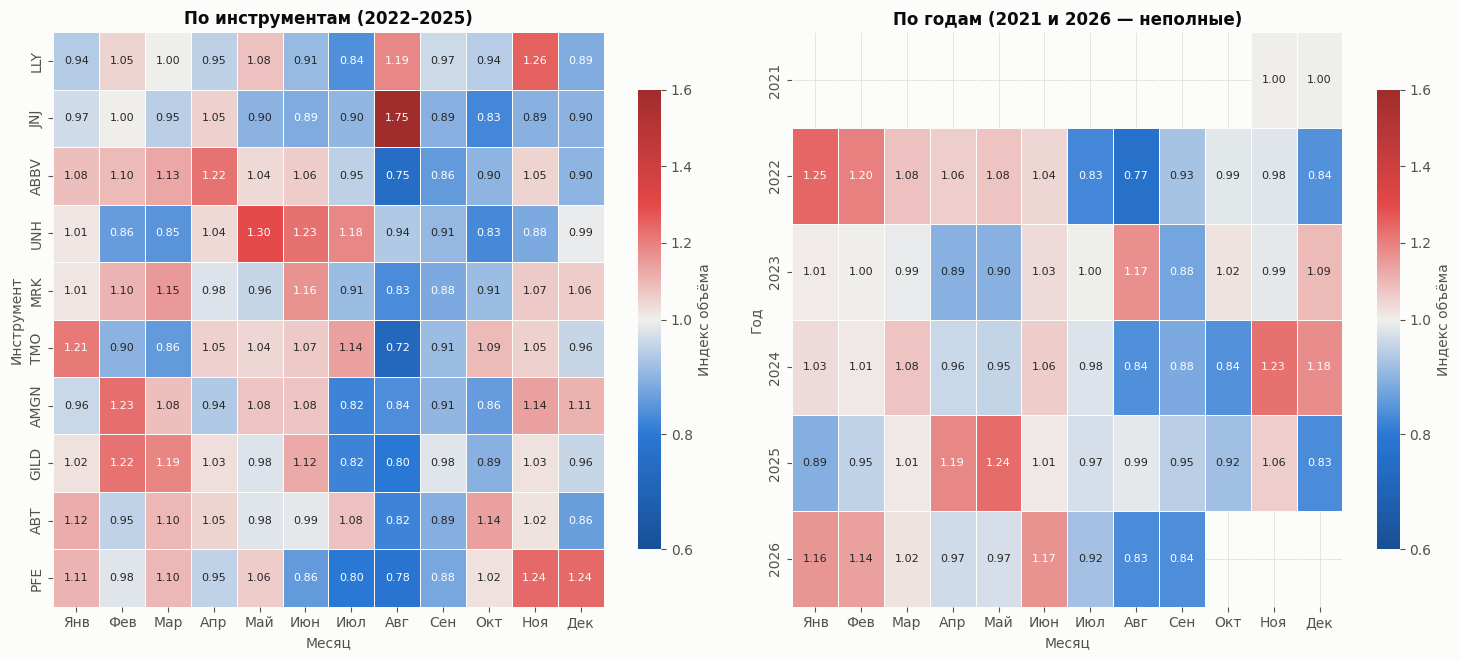

Самые активные месяцы: Ноя (1.06), Янв (1.04), Май (1.04)
Самые тихие месяцы:    Сен (0.91), Авг (0.94), Окт (0.94)
Самые активные месяцы по годам: 2021: Ноя (1.00), 2022: Янв (1.25), 2023: Авг (1.17), 2024: Ноя (1.23), 2025: Май (1.24), 2026: Июн (1.17)


In [12]:
month_report("health_care")

### Акции сектора Materials (сырьё и материалы)

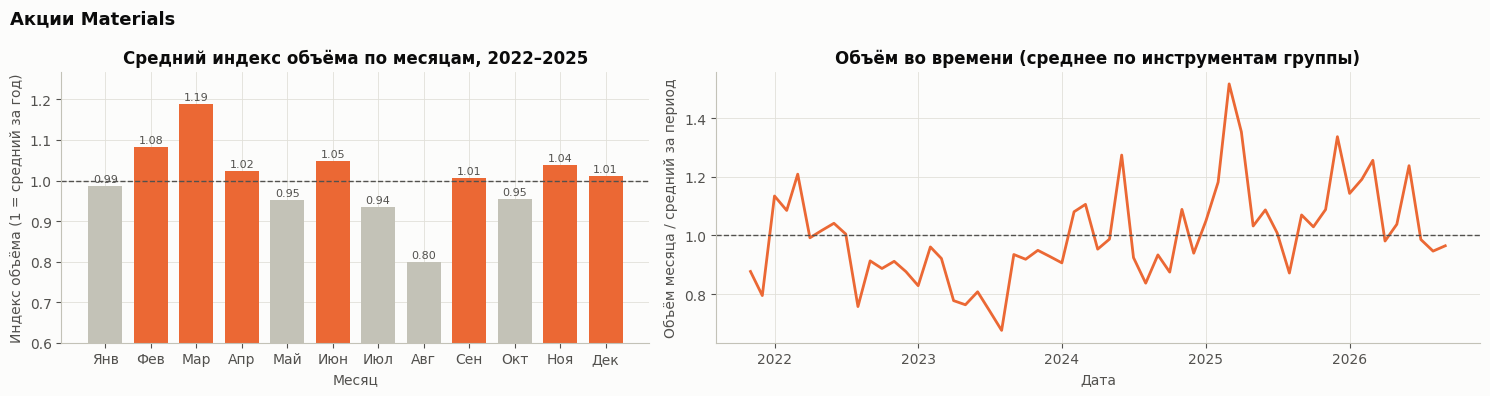

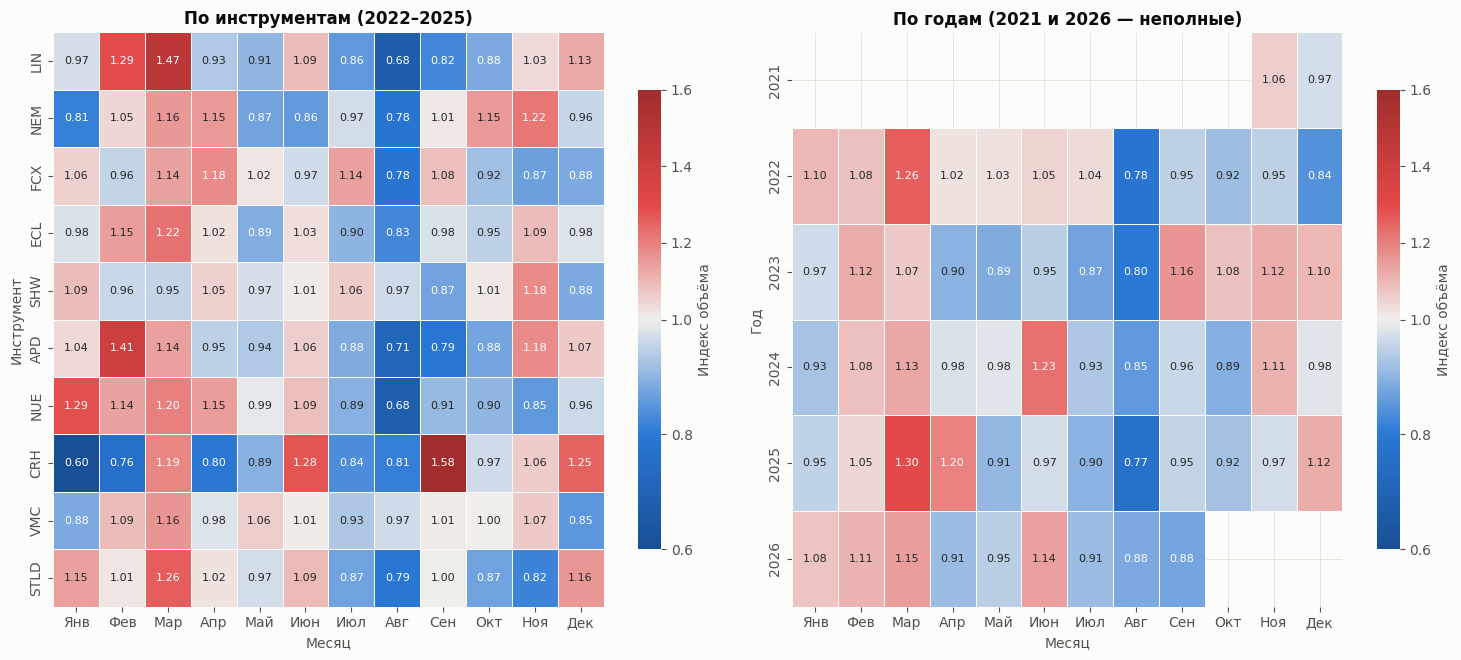

Самые активные месяцы: Мар (1.19), Фев (1.08), Июн (1.05)
Самые тихие месяцы:    Авг (0.80), Июл (0.94), Май (0.95)
Самые активные месяцы по годам: 2021: Ноя (1.06), 2022: Мар (1.26), 2023: Сен (1.16), 2024: Июн (1.23), 2025: Мар (1.30), 2026: Мар (1.15)


In [13]:
month_report("materials")

### Голубые фишки

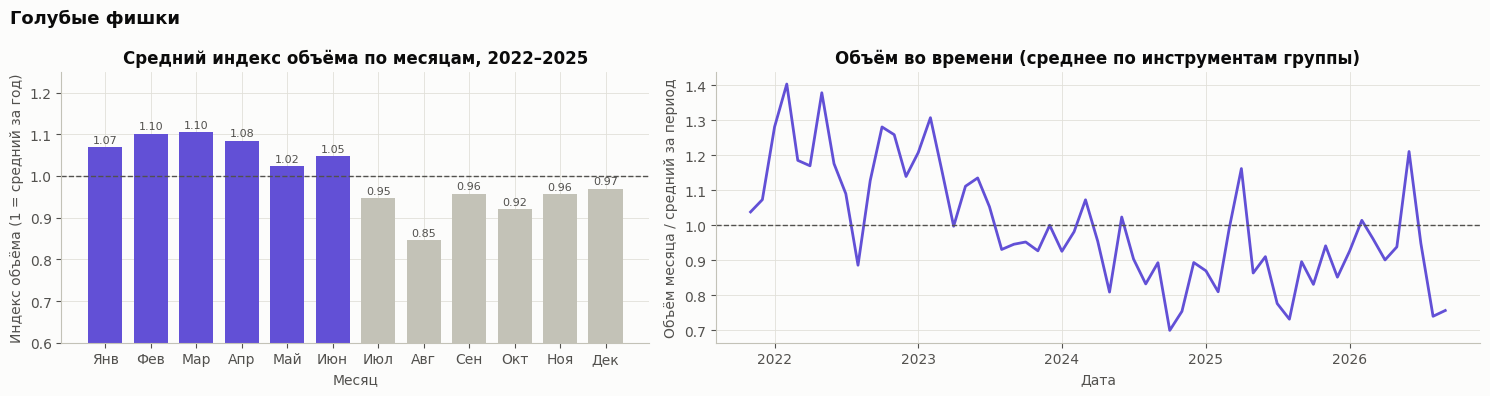

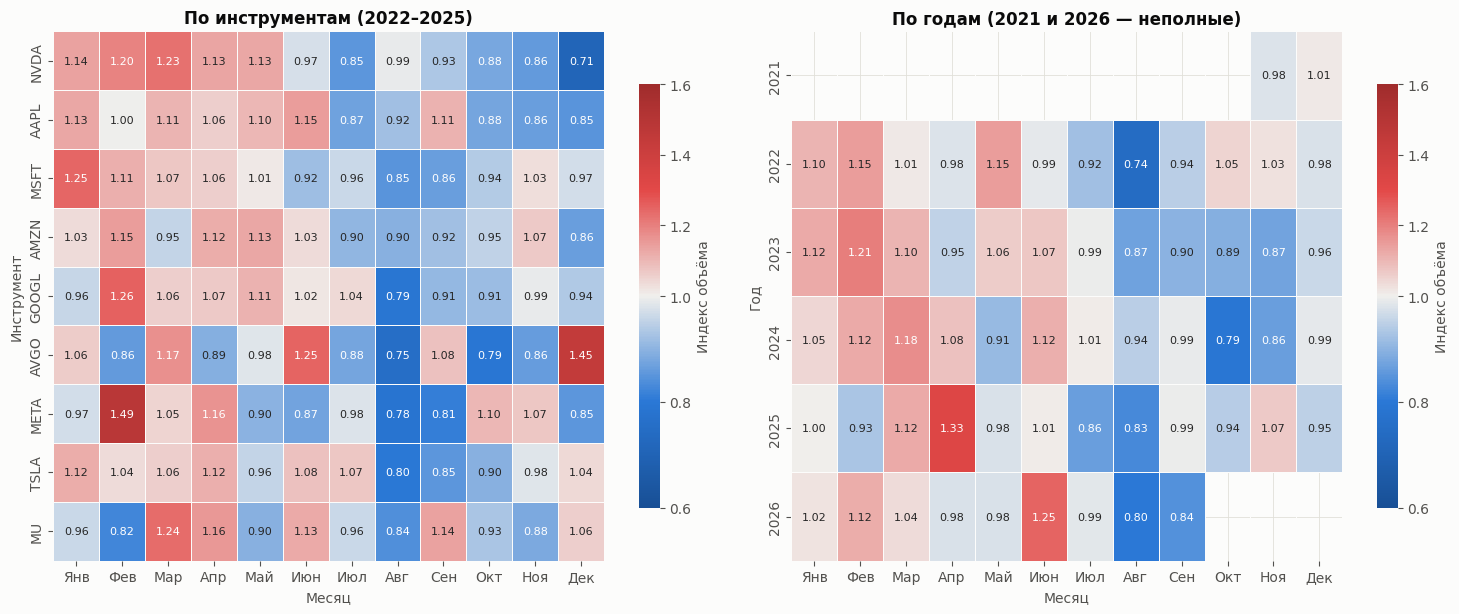

Самые активные месяцы: Мар (1.10), Фев (1.10), Апр (1.08)
Самые тихие месяцы:    Авг (0.85), Окт (0.92), Июл (0.95)
Самые активные месяцы по годам: 2021: Дек (1.01), 2022: Фев (1.15), 2023: Фев (1.21), 2024: Мар (1.18), 2025: Апр (1.33), 2026: Июн (1.25)


In [14]:
month_report("blue_chips")

#### Вывод по разделу 2

**Общая картина.** Сезонность есть, но умеренная: средние по месяцам отклоняются от годового уровня на 5–20%. Заметно сильнее на объём влияют разовые события. Ярче всего это видно в апреле 2025 года: у фьючерсов на индексы объём в 1.5 раза выше среднего за год, у голубых фишек — в 1.33 раза, у Materials и Health Care — примерно в 1.2 раза.

**По группам:**
- **Фьючерсы на индексы.** Самые активные месяцы — январь–апрель (1.07–1.10). Самый тихий — декабрь (0.84), затем июль и август (0.93–0.94). Декабрьский провал — самый глубокий среди всех групп: перед праздниками крупные участники сворачивают активность.
- **Фьючерсы на металлы** живут по своему календарю. Пик осенью (октябрь 1.08, ноябрь 1.07) и в феврале (1.05), минимум в августе (0.87) и июле (0.91). Главное событие периода — январь 2026 года: объём почти вдвое выше среднего за год (1.97). Этот же всплеск виден в волатильности металлов (раздел 6). Причину всплеска мы не исследовали.
- **Акции Health Care** — самая ровная группа. Все месяцы в пределах 0.91–1.06, явных сезонов нет. Пики объёма у отдельных компаний (например, JNJ в августе — 1.75) связаны с их собственными событиями (отчётность, новости о препаратах), а не с календарём.
- **Акции Materials** — самая выраженная сезонность среди акций. Март — 1.19, самый активный месяц из всех групп. Август — 0.80, самый тихий.
- **Голубые фишки.** Активны февраль–апрель (1.08–1.10), тише всего август (0.85) и октябрь (0.92).

**Общее для всех групп** — летнее затишье в июле и августе. Для акций март — один из самых активных месяцев. Это вероятно связано с квартальной экспирацией опционов и фьючерсов и ребалансировкой индексов в третью пятницу марта, но отдельно мы это не проверяли.

**Что это значит для проекта.** Месяц сам по себе — слабый признак для модели. Полезнее относительный объём — объём текущего периода по сравнению с его обычным уровнем: он улавливает и сезонные провалы, и всплески от событий. Гипотеза для проверки на следующих этапах: в тихие месяцы (июль, август, декабрь) выходы из консолидации чаще оказываются ложными.

## 3. Объём торгов по дням недели

**Вопрос.** В какие дни недели торгуют активнее? Сохраняется ли это из года в год?

**Как считали.** Тот же индекс объёма: дневной объём, делённый на средний дневной объём года этого инструмента, — и усреднение по дням недели. Считаем за каждый год отдельно и за весь период. Здесь можно брать и неполные годы: индекс считается внутри года, поэтому неполнота года на сравнение дней не влияет.

**Особенность фьючерсов.** Торговый день на бирже CME начинается вечером накануне, в 18:00 по Нью-Йорку. Поэтому торговля в воскресенье вечером относится к понедельнику, а торговля в четверг вечером — к пятнице.

**На графиках для каждой группы:** средний индекс по дням недели за весь период, тепловая карта «год × день недели» и тепловая карта по инструментам.

In [15]:
wd = vol[vol["weekday"] <= 4]
print("Торговых дней, выпавших на выходные:", int((vol["weekday"] > 4).sum()))
wd_inst = wd.groupby(["ticker", "weekday"])["idx"].mean().unstack()

def weekday_report(group):
    tick = members(group)
    w = wd[wd["ticker"].isin(tick)]
    overall = wd_inst.loc[tick].mean()
    by_year = w.groupby(["ticker", "year", "weekday"])["idx"].mean().groupby(["year", "weekday"]).mean().unstack()

    fig, axes = plt.subplots(1, 3, figsize=(16, 0.32 * len(tick) + 3.2), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})
    ax = axes[0]
    ax.bar(range(5), overall, color=[GROUP_COLOR[group] if x >= 1 else BASE for x in overall], width=0.7)
    for i, x in enumerate(overall):
        ax.text(i, x + 0.005, f"{x:.2f}", ha="center", fontsize=9, color=INK2)
    ax.axhline(1, color=INK2, lw=1, ls="--"); ax.set_ylim(0.8, max(1.12, overall.max() + 0.03))
    ax.set_xticks(range(5), DAYS); ax.set_xlabel("День недели"); ax.set_ylabel("Индекс объёма (1 = средний за год)")
    ax.set_title("Весь период")
    heatmap(axes[1], by_year.rename(columns=dict(enumerate(DAYS))), DIV, "Индекс объёма", center=1, vmin=0.7, vmax=1.3)
    axes[1].set_xlabel("День недели"); axes[1].set_ylabel("Год"); axes[1].set_title("По годам")
    heatmap(axes[2], wd_inst.loc[tick].rename(columns=dict(enumerate(DAYS))), DIV, "Индекс объёма", center=1, vmin=0.7, vmax=1.3)
    axes[2].set_xlabel("День недели"); axes[2].set_ylabel("Инструмент"); axes[2].set_title("По инструментам")
    fig.suptitle(GROUP_NAME[group], x=0.01, ha="left", fontweight="bold", fontsize=13)
    plt.tight_layout(); plt.show()
    s = overall.rename(index=dict(enumerate(DAYS)))
    print(f"Самый активный день: {s.idxmax()} ({s.max():.2f}), самый тихий: {s.idxmin()} ({s.min():.2f})")
    print("Самый активный день по годам:", ", ".join(f"{y}: {DAYS[d]}" for y, d in by_year.idxmax(axis=1).items()))
    print("Самый тихий день по годам:   ", ", ".join(f"{y}: {DAYS[d]}" for y, d in by_year.idxmin(axis=1).items()))

Торговых дней, выпавших на выходные: 0


### Фьючерсы на фондовые индексы

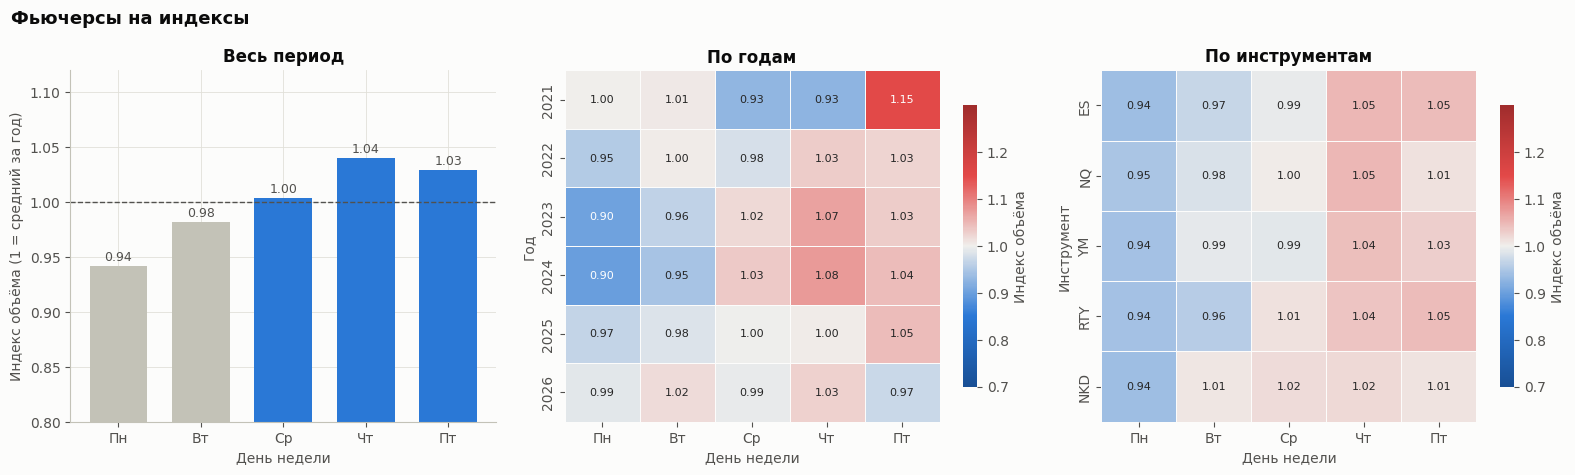

Самый активный день: Чт (1.04), самый тихий: Пн (0.94)
Самый активный день по годам: 2021: Пт, 2022: Чт, 2023: Чт, 2024: Чт, 2025: Пт, 2026: Чт
Самый тихий день по годам:    2021: Чт, 2022: Пн, 2023: Пн, 2024: Пн, 2025: Пн, 2026: Пт


In [16]:
weekday_report("indices")

### Фьючерсы на металлы

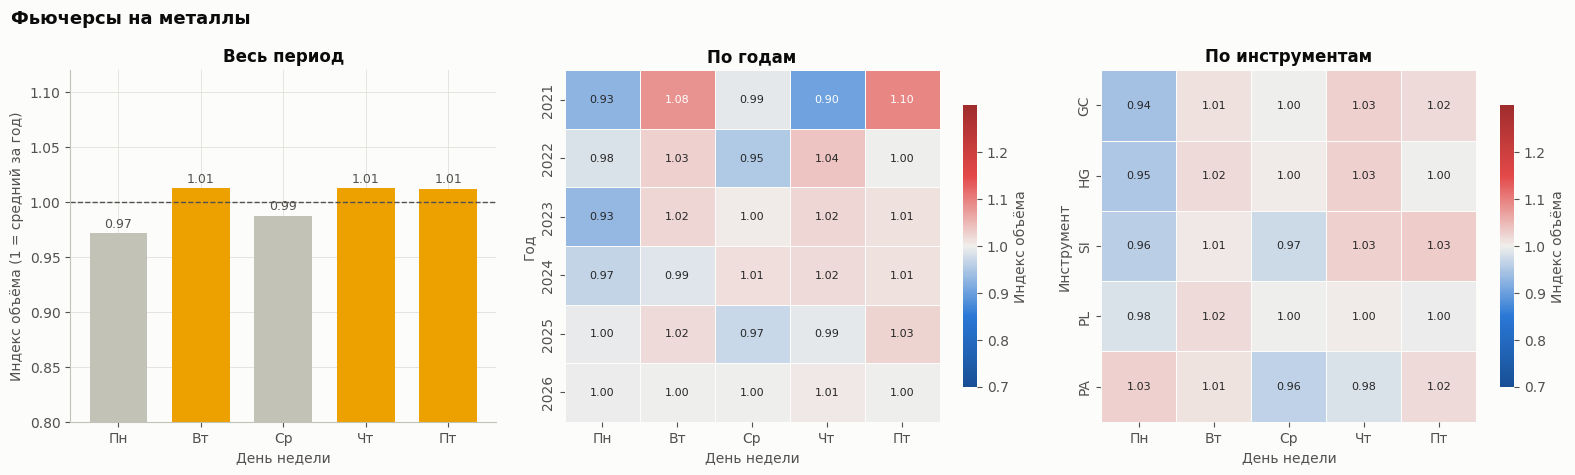

Самый активный день: Чт (1.01), самый тихий: Пн (0.97)
Самый активный день по годам: 2021: Пт, 2022: Чт, 2023: Чт, 2024: Чт, 2025: Пт, 2026: Чт
Самый тихий день по годам:    2021: Чт, 2022: Ср, 2023: Пн, 2024: Пн, 2025: Ср, 2026: Пн


In [17]:
weekday_report("metals")

### Акции сектора Health Care (здравоохранение)

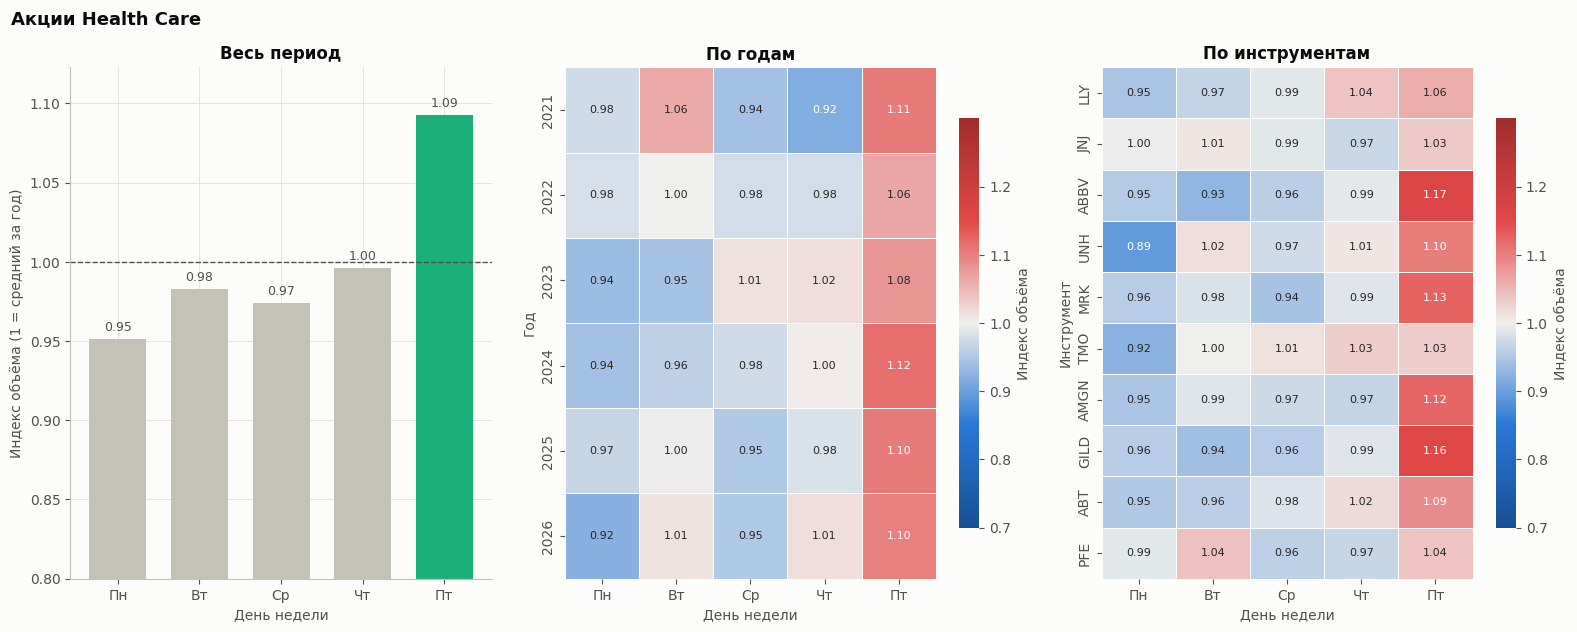

Самый активный день: Пт (1.09), самый тихий: Пн (0.95)
Самый активный день по годам: 2021: Пт, 2022: Пт, 2023: Пт, 2024: Пт, 2025: Пт, 2026: Пт
Самый тихий день по годам:    2021: Чт, 2022: Ср, 2023: Пн, 2024: Пн, 2025: Ср, 2026: Пн


In [18]:
weekday_report("health_care")

### Акции сектора Materials (сырьё и материалы)

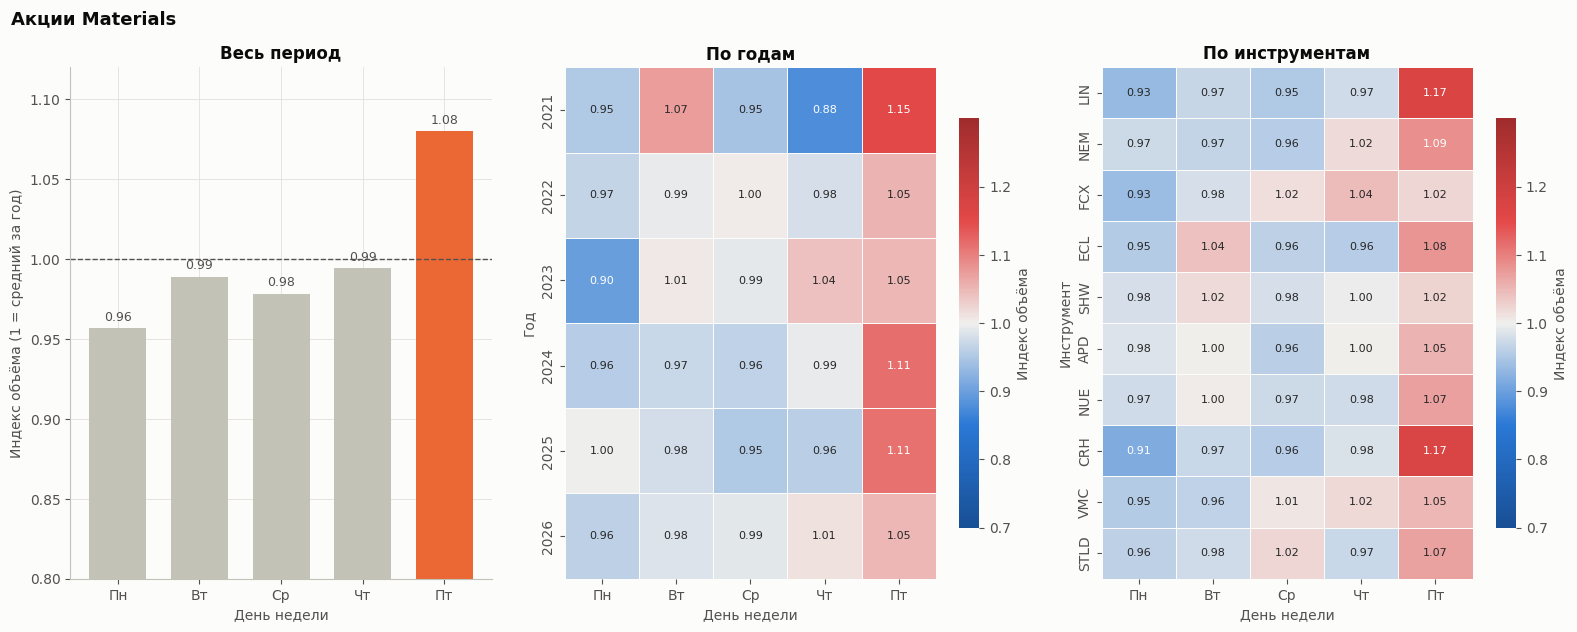

Самый активный день: Пт (1.08), самый тихий: Пн (0.96)
Самый активный день по годам: 2021: Пт, 2022: Пт, 2023: Пт, 2024: Пт, 2025: Пт, 2026: Пт
Самый тихий день по годам:    2021: Чт, 2022: Пн, 2023: Пн, 2024: Пн, 2025: Ср, 2026: Пн


In [19]:
weekday_report("materials")

### Голубые фишки

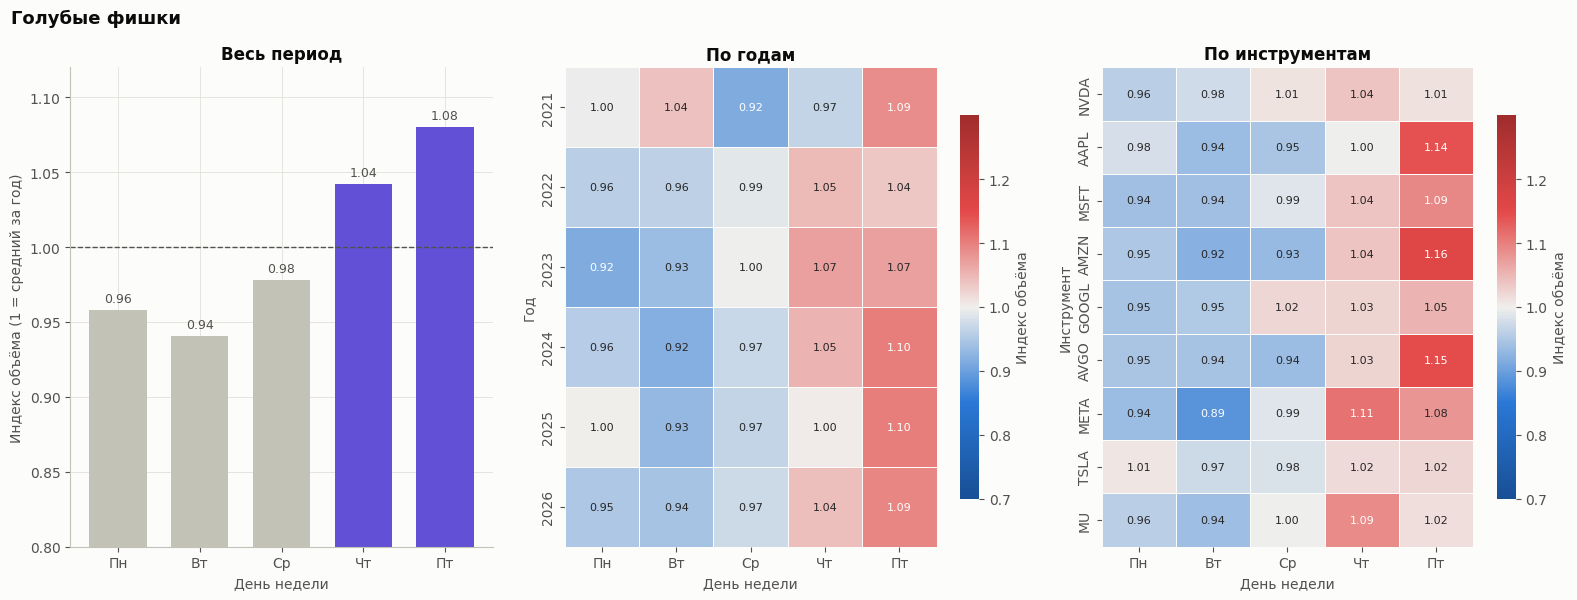

Самый активный день: Пт (1.08), самый тихий: Вт (0.94)
Самый активный день по годам: 2021: Пт, 2022: Чт, 2023: Чт, 2024: Пт, 2025: Пт, 2026: Пт
Самый тихий день по годам:    2021: Ср, 2022: Пн, 2023: Пн, 2024: Вт, 2025: Вт, 2026: Вт


In [20]:
weekday_report("blue_chips")

#### Вывод по разделу 3

**Понедельник — тихий день почти везде.** Объём на 3–6% ниже среднего по году. Это верно для четырёх групп из пяти; у голубых фишек самый тихий день — вторник (0.94).

**В конце недели фьючерсы и акции ведут себя по-разному:**
- **Акции:** самый активный день — пятница, и это повторяется каждый год во всех трёх группах акций. Объём на 8–9% выше среднего: Health Care 1.09, Materials 1.08, голубые фишки 1.08. Вероятное объяснение — по пятницам истекают опционы, а в квартальные пятницы ещё и ребалансируются индексы, что требует от фондов больших сделок.
- **Фьючерсы на индексы:** пик в четверг (1.04), пятница почти на том же уровне (1.03). Четверг активнее пятницы в 2022–2024 годах.
- **Фьючерсы на металлы:** дни недели почти не различаются (от 0.97 до 1.01). Активность металлов определяется не календарём недели, а новостями и мировыми рынками.

**Картина устойчива по годам**, особенно у акций, где пятница лидирует все пять лет. Значит, день недели можно использовать как признак для модели, но эффект небольшой — порядка ±5–9%.

## 4. Объём торгов внутри торгового дня

**Вопрос.** В какие часы рынок наиболее активен, а в какие торговля почти замирает?

**Как считали.** Берём 15-минутные свечи и переводим время в нью-йоркское (с учётом перехода на летнее время). Для каждого торгового дня считаем, какая доля дневного объёма пришлась на каждый час, и усредняем эти доли по всем дням. Так каждый день весит одинаково, и единичные дни паники или экспирации не перекашивают картину. Сумма долей по часам — 100%.

**Ориентиры по времени (Нью-Йорк):**
- 8:30 — выход основной макроэкономической статистики США (занятость, инфляция);
- 9:30–16:00 — основная сессия фондовой биржи (на графиках акций выделена серым);
- 4:00–9:30 и 16:00–20:00 — расширенные сессии для акций;
- 17:00–18:00 — ежедневный технический перерыв на CME, фьючерсы не торгуются;
- ночные часы по Нью-Йорку — это дневная торговля в Азии (примерно 19:00–3:00) и в Европе (примерно 3:00–11:30).

**Ограничение.** Аукцион закрытия фондовой биржи (большая сделка ровно в 16:00) не попадает в 15-минутные свечи, поэтому реальная доля конца дня у акций ещё выше, чем на графиках.

**На графиках для каждой группы:** средняя доля объёма по часам и тепловая карта по инструментам.

In [21]:
def hour_profile(ticker):
    if ticker in FUTURES:
        bars = pd.read_parquet(PROCESSED_DIR / "futures_continuous" / f"{ticker}_15min.parquet",
                               columns=["time", "session_end_date", "volume"])
        day = bars["session_end_date"]
    else:
        bars = pd.read_parquet(PROCESSED_DIR / "stocks" / f"{ticker}_15min.parquet", columns=["time", "split_adj_volume"])
        bars = bars.rename(columns={"split_adj_volume": "volume"})
        day = bars["time"].dt.tz_convert(NY).dt.date
    hour = bars["time"].dt.tz_convert(NY).dt.hour
    table = bars.groupby([day, hour])["volume"].sum().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
    return table.div(table.sum(axis=1), axis=0).mean() * 100

hours = pd.DataFrame({t: hour_profile(t) for t in ORDER}).T

def hour_report(group):
    tick = members(group)
    profile = hours.loc[tick].mean()
    is_stock = group not in ("indices", "metals")
    fig, ax = plt.subplots(figsize=(14, 3.8))
    if is_stock:
        ax.axvspan(9.5 - 0.5, 16 - 0.5, color=GRID, alpha=0.6, lw=0, zorder=0)
    ax.bar(range(24), profile, color=GROUP_COLOR[group], width=0.8)
    for h, x in profile.items():
        if x >= 0.5:
            ax.text(h, x + 0.2, f"{x:.1f}", ha="center", fontsize=8, color=INK2)
    ax.set_xticks(range(24), [f"{h:02d}:00" for h in range(24)], rotation=45)
    ax.set_xlabel("Час начала (время Нью-Йорка)"); ax.set_ylabel("Доля объёма дня, %")
    title = f"{GROUP_NAME[group]}: средняя доля объёма по часам"
    ax.set_title(title + (" (серым — основная сессия 9:30–16:00)" if is_stock else " (17:00–18:00 — перерыв CME)"))
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(15, 0.42 * len(tick) + 1.8))
    heatmap(ax, hours.loc[tick].rename(columns=lambda h: f"{h:02d}"), SEQ, "Доля объёма дня, %", fmt=".1f", annot_size=7)
    ax.set_xlabel("Час начала (время Нью-Йорка)"); ax.set_ylabel("Инструмент")
    ax.set_title("Доля объёма по часам и инструментам, %")
    plt.tight_layout(); plt.show()

    active = profile.nlargest(3); quiet = profile[profile > 0.05].nsmallest(3)
    print("Самые активные часы:", ", ".join(f"{h:02d}:00 ({x:.1f}%)" for h, x in active.items()))
    print("Самые тихие часы (из часов с торговлей):", ", ".join(f"{h:02d}:00 ({x:.1f}%)" for h, x in quiet.items()))
    if is_stock:
        session = profile.loc[10:15]
        print("Самые тихие часы внутри основной сессии:", ", ".join(f"{h:02d}:00 ({x:.1f}%)" for h, x in session.nsmallest(2).items()))
        print(f"Доля расширенных сессий (до 9:00 и после 16:00): {profile.loc[list(range(0, 9)) + list(range(16, 24))].sum():.1f}%")
    else:
        print(f"Доля часов основной сессии фондовой биржи (9:00–16:00): {profile.loc[9:15].sum():.1f}%")
        print(f"Доля ночных и утренних часов (18:00–8:00): {profile.loc[list(range(18, 24)) + list(range(0, 8))].sum():.1f}%")

### Фьючерсы на фондовые индексы

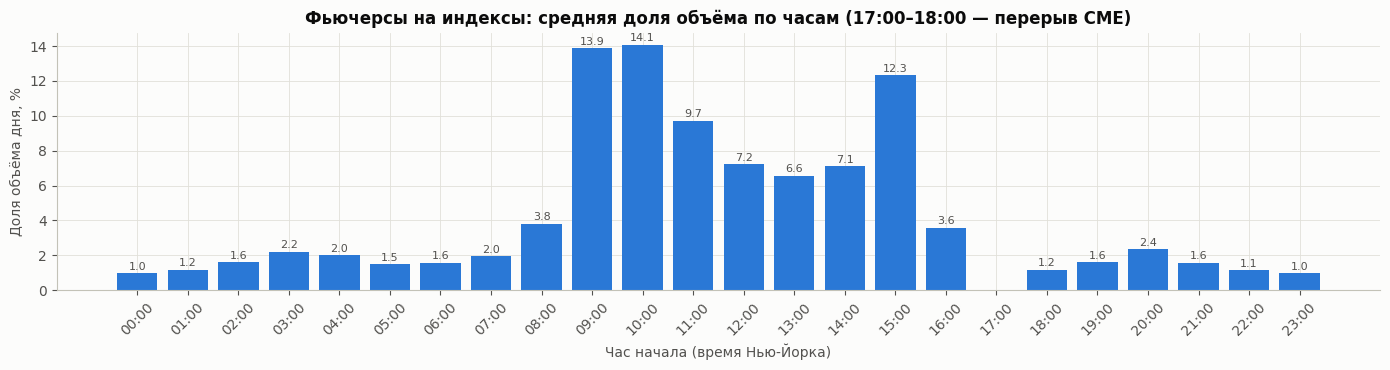

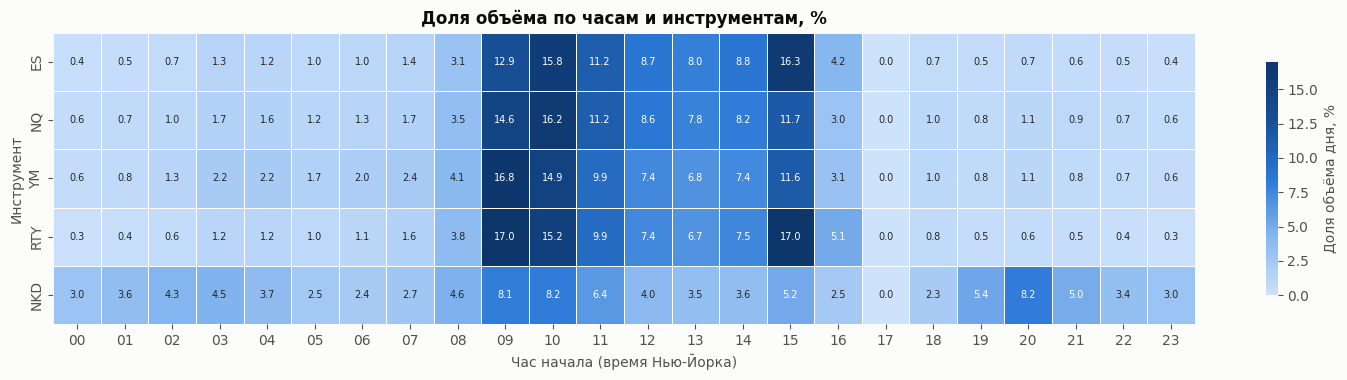

Самые активные часы: 10:00 (14.1%), 09:00 (13.9%), 15:00 (12.3%)
Самые тихие часы (из часов с торговлей): 00:00 (1.0%), 23:00 (1.0%), 22:00 (1.1%)
Доля часов основной сессии фондовой биржи (9:00–16:00): 70.9%
Доля ночных и утренних часов (18:00–8:00): 21.7%


In [22]:
hour_report("indices")

### Фьючерсы на металлы

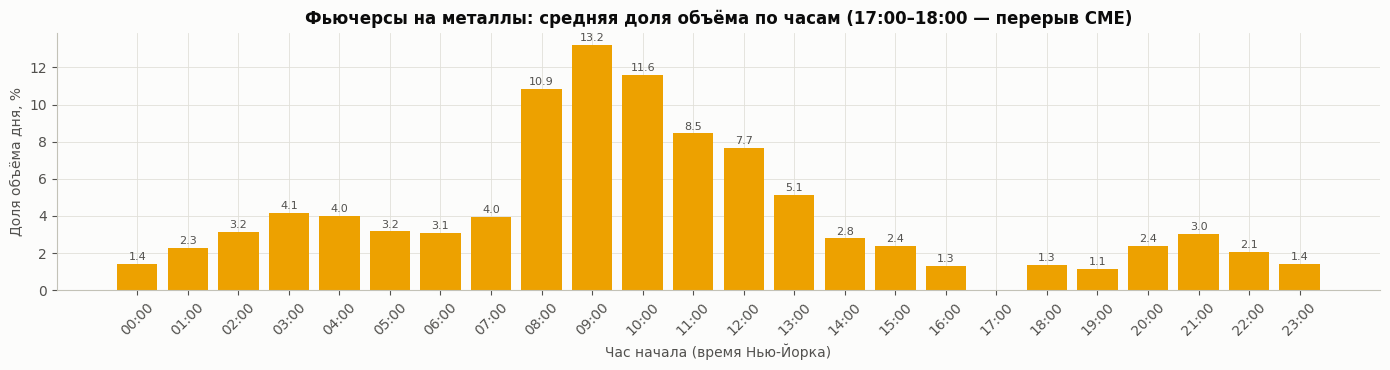

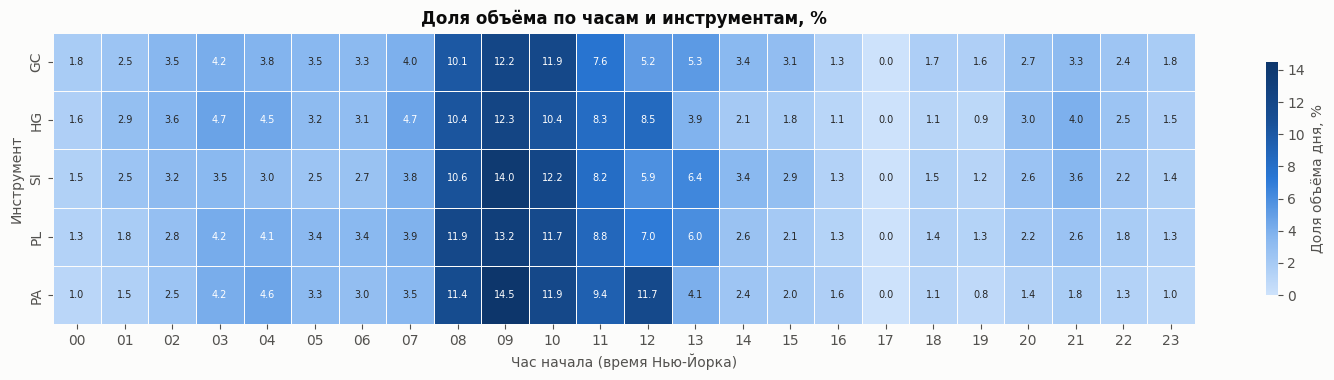

Самые активные часы: 09:00 (13.2%), 10:00 (11.6%), 08:00 (10.9%)
Самые тихие часы (из часов с торговлей): 19:00 (1.1%), 16:00 (1.3%), 18:00 (1.3%)
Доля часов основной сессии фондовой биржи (9:00–16:00): 51.2%
Доля ночных и утренних часов (18:00–8:00): 36.6%


In [23]:
hour_report("metals")

### Акции сектора Health Care (здравоохранение)

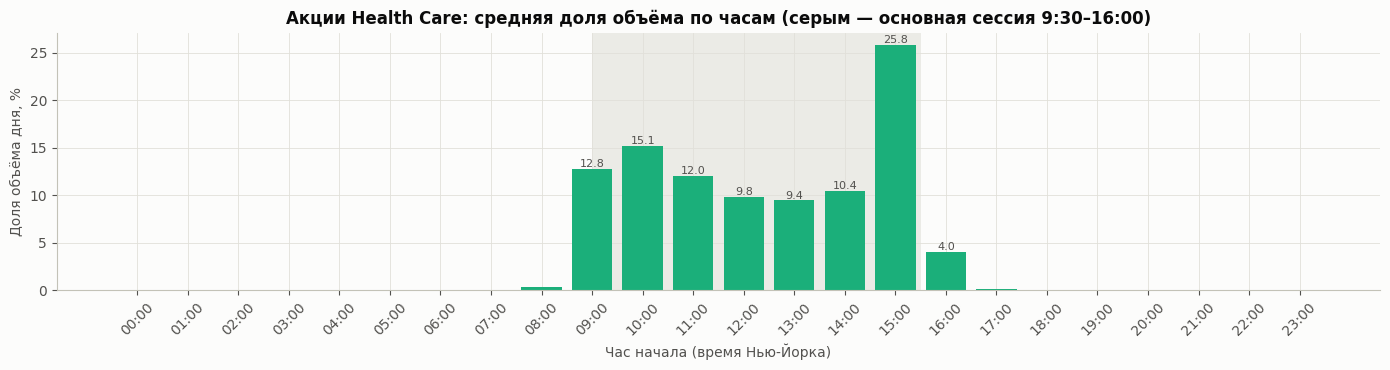

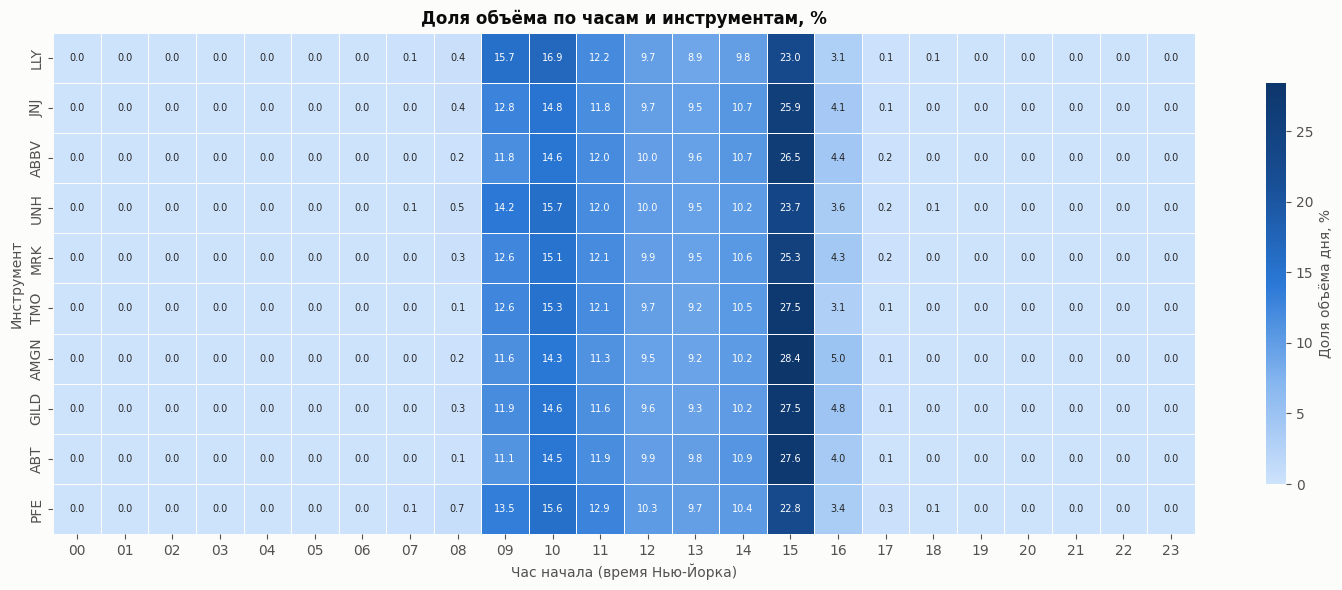

Самые активные часы: 15:00 (25.8%), 10:00 (15.1%), 09:00 (12.8%)
Самые тихие часы (из часов с торговлей): 17:00 (0.1%), 08:00 (0.3%), 16:00 (4.0%)
Самые тихие часы внутри основной сессии: 13:00 (9.4%), 12:00 (9.8%)
Доля расширенных сессий (до 9:00 и после 16:00): 4.6%


In [24]:
hour_report("health_care")

### Акции сектора Materials (сырьё и материалы)

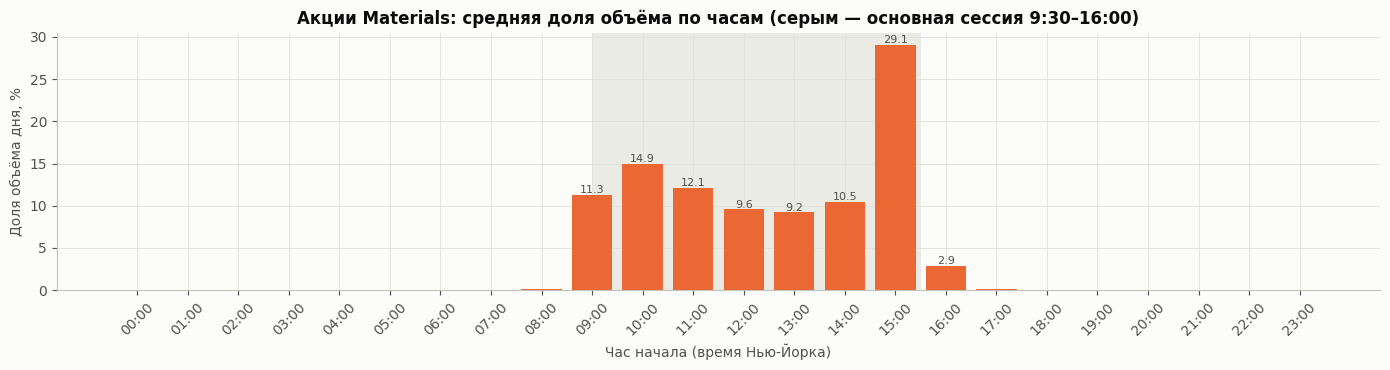

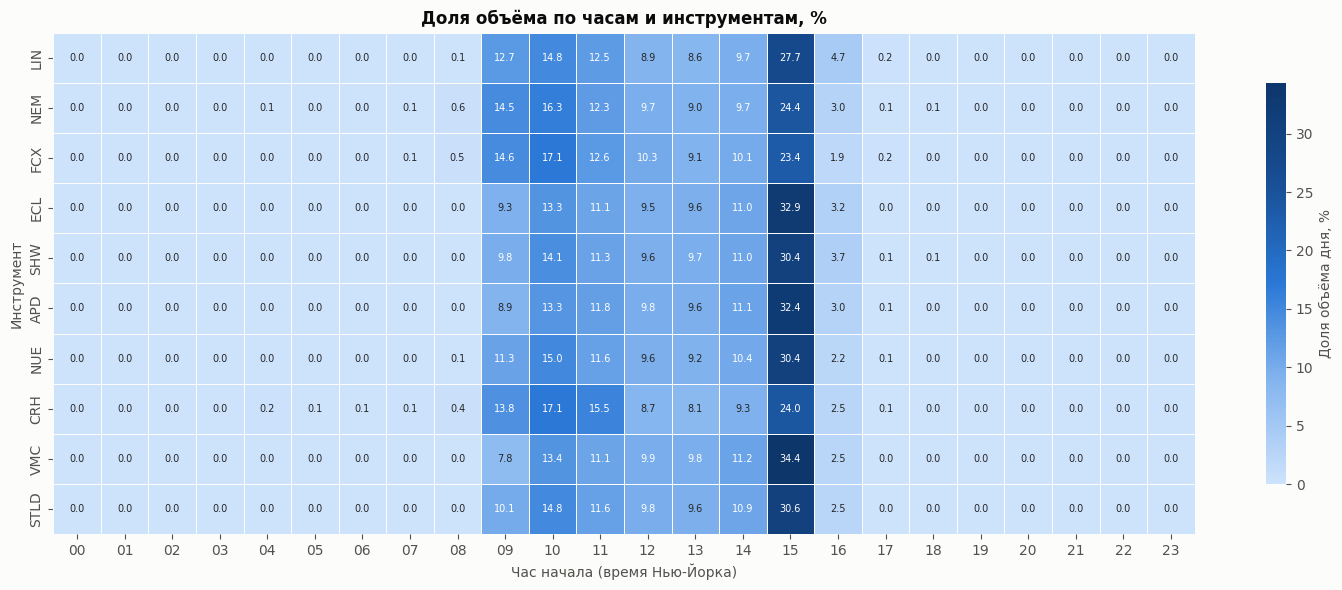

Самые активные часы: 15:00 (29.1%), 10:00 (14.9%), 11:00 (12.1%)
Самые тихие часы (из часов с торговлей): 17:00 (0.1%), 08:00 (0.2%), 16:00 (2.9%)
Самые тихие часы внутри основной сессии: 13:00 (9.2%), 12:00 (9.6%)
Доля расширенных сессий (до 9:00 и после 16:00): 3.3%


In [25]:
hour_report("materials")

### Голубые фишки

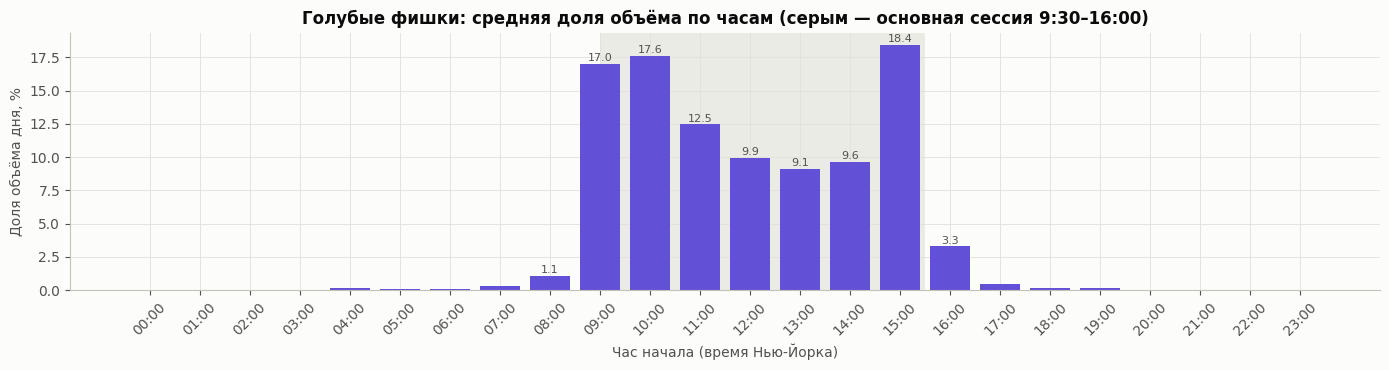

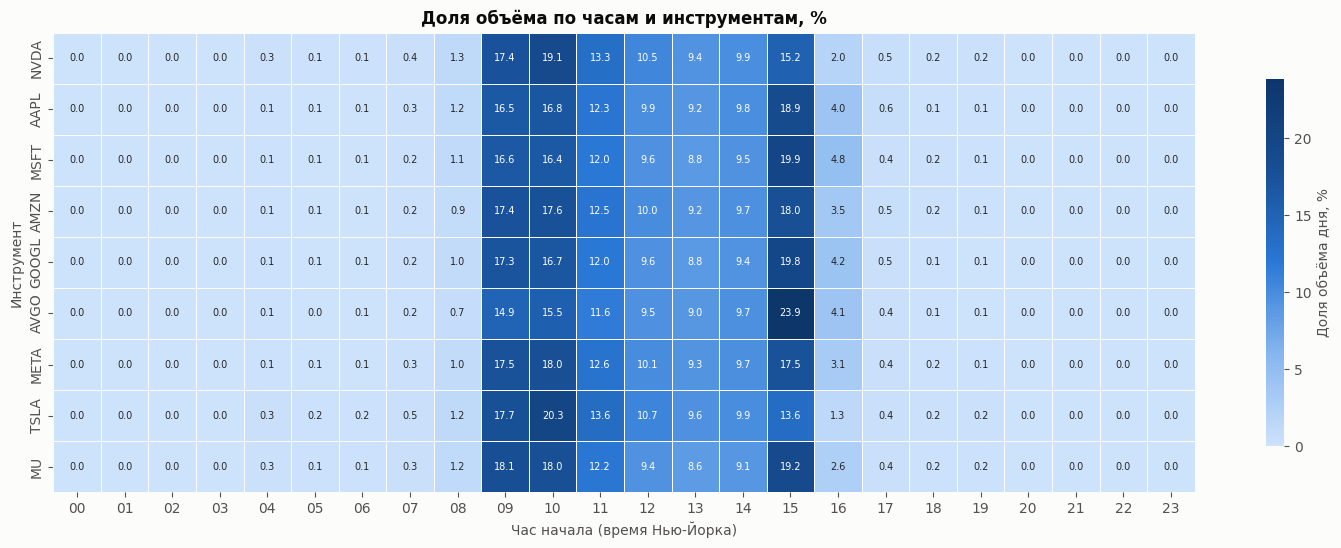

Самые активные часы: 15:00 (18.4%), 10:00 (17.6%), 09:00 (17.0%)
Самые тихие часы (из часов с торговлей): 05:00 (0.1%), 06:00 (0.1%), 19:00 (0.1%)
Самые тихие часы внутри основной сессии: 13:00 (9.1%), 14:00 (9.6%)
Доля расширенных сессий (до 9:00 и после 16:00): 5.8%


In [26]:
hour_report("blue_chips")

#### Вывод по разделу 4

Распределение объёма внутри дня — самый сильный «календарный» эффект в данных: в активные часы торгуется в 10 и более раз больше, чем в тихие.

- **Фьючерсы на индексы.**
    - Активнее всего торгуются в первые часы основной сессии фондового рынка: 9:00 и 10:00 (около 14% объёма дня каждый час) и в последний час торгов акциями, 15:00 (12.3%).
    - На часы основной сессии приходится 71% объёма, ночью и ранним утром (18:00–8:00) — 22%.
    - Самые тихие часы — 22:00–00:00 (около 1% в час).
    - Исключение — японский Nikkei (NKD): на часы основной сессии США у него приходится менее 40% объёма, остальное — азиатские часы.
- **Фьючерсы на металлы.**
    - Пик раньше, чем у индексов: 8:00–10:00 (10.9%, 13.2% и 11.6%). Торговля металлами в Нью-Йорке открывается в 8:20, примерно тогда же выходит статистика США.
    - После 13:00 активность быстро затухает: торги на бирже COMEX в Нью-Йорке завершаются в 13:30.
    - Ночная и утренняя торговля (Азия и Европа) — 37% объёма, заметно больше, чем у индексов.
- **Акции — классическая U-образная кривая.**
    - Пик на открытии (9:30–11:00) и особенно в последний час торгов: 15:00–16:00 — 26% объёма дня у Health Care и 29% у Materials, и это без аукциона закрытия.
    - Провал в обеденные часы 12:00–14:00 (около 9–10% в час).
    - Расширенные сессии дают всего 3–6% объёма.
- **Голубые фишки отличаются от остальных акций.** Объём распределён ровнее: последний час — 18%, открытие — 17–18%. Доля расширенных сессий больше (5.8%): по крупнейшим компаниям активно торгуют до и после основной сессии, особенно после выхода отчётности.

**Что это значит для проекта.** Для внутридневных таймфреймов час — обязательный признак. Узкий диапазон цены ночью у фьючерсов или в обед у акций — не настоящая консолидация, а просто отсутствие торговли, и индикатор не должен путать одно с другим. Поэтому диапазон и объём бара стоит сравнивать с типичными значениями для этого же часа. Гипотеза для проверки: выходы из консолидации в активные часы (открытие и закрытие фондового рынка) надёжнее, чем в тихие.

## 5. Корреляции инструментов на дневном таймфрейме

**Вопрос.** Какие инструменты движутся вместе, а какие независимо друг от друга?

**Как считали.** Корреляция Пирсона дневных **доходностей** — процентных изменений цены от закрытия к закрытию (точнее, логарифмов отношения цен). Корреляцию самих цен не считаем: у любых двух инструментов, которые росли за пять лет, она получится высокой, даже если между ними нет никакой связи. Для акций доходность учитывает дивиденды. Берём только дни, когда торговались все инструменты, — 1 218 дней.

**Как читать.** Корреляция +1 — инструменты движутся синхронно, 0 — независимо, −1 — в противоположные стороны. Для дневных доходностей значения выше 0.7 — очень сильная связь, 0.4–0.7 — заметная, ниже 0.2 — слабая.

Нюанс: торговый день фьючерсов заканчивается в 17:00, а акций — в 16:00 по Нью-Йорку. Движение фьючерса в последний час «не видно» акциям, это немного занижает корреляцию между фьючерсами и акциями.

Общих торговых дней: 1218 (16.11.2021 — 30.09.2026)


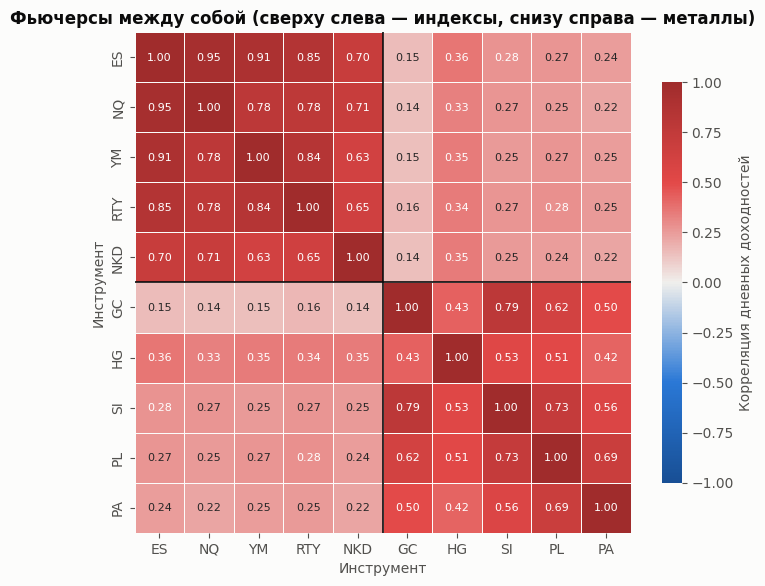

In [27]:
closes = pd.DataFrame({t: d.set_index("trade_date")["ret_close"] for t, d in daily.items()})
returns = np.log(closes).diff().dropna(how="any")
corr = returns[ORDER].corr()
print(f"Общих торговых дней: {len(returns)} ({returns.index.min():%d.%m.%Y} — {returns.index.max():%d.%m.%Y})")

def group_lines(ax, tickers_, vertical=True, horizontal=True):
    bounds = np.cumsum(pd.Series([GROUP[t] for t in tickers_]).value_counts(sort=False).reindex(
        [g for g in GROUP_IDS if g in {GROUP[t] for t in tickers_}]).values)[:-1]
    for b in bounds:
        if horizontal: ax.axhline(b, color=INK, lw=1.2)
        if vertical: ax.axvline(b, color=INK, lw=1.2)

fig, ax = plt.subplots(figsize=(8, 6.5))
heatmap(ax, corr.loc[FUTURES, FUTURES], DIV, "Корреляция дневных доходностей", vmin=-1, vmax=1, center=0)
group_lines(ax, FUTURES)
ax.set_xlabel("Инструмент"); ax.set_ylabel("Инструмент")
ax.set_title("Фьючерсы между собой (сверху слева — индексы, снизу справа — металлы)")
plt.show()

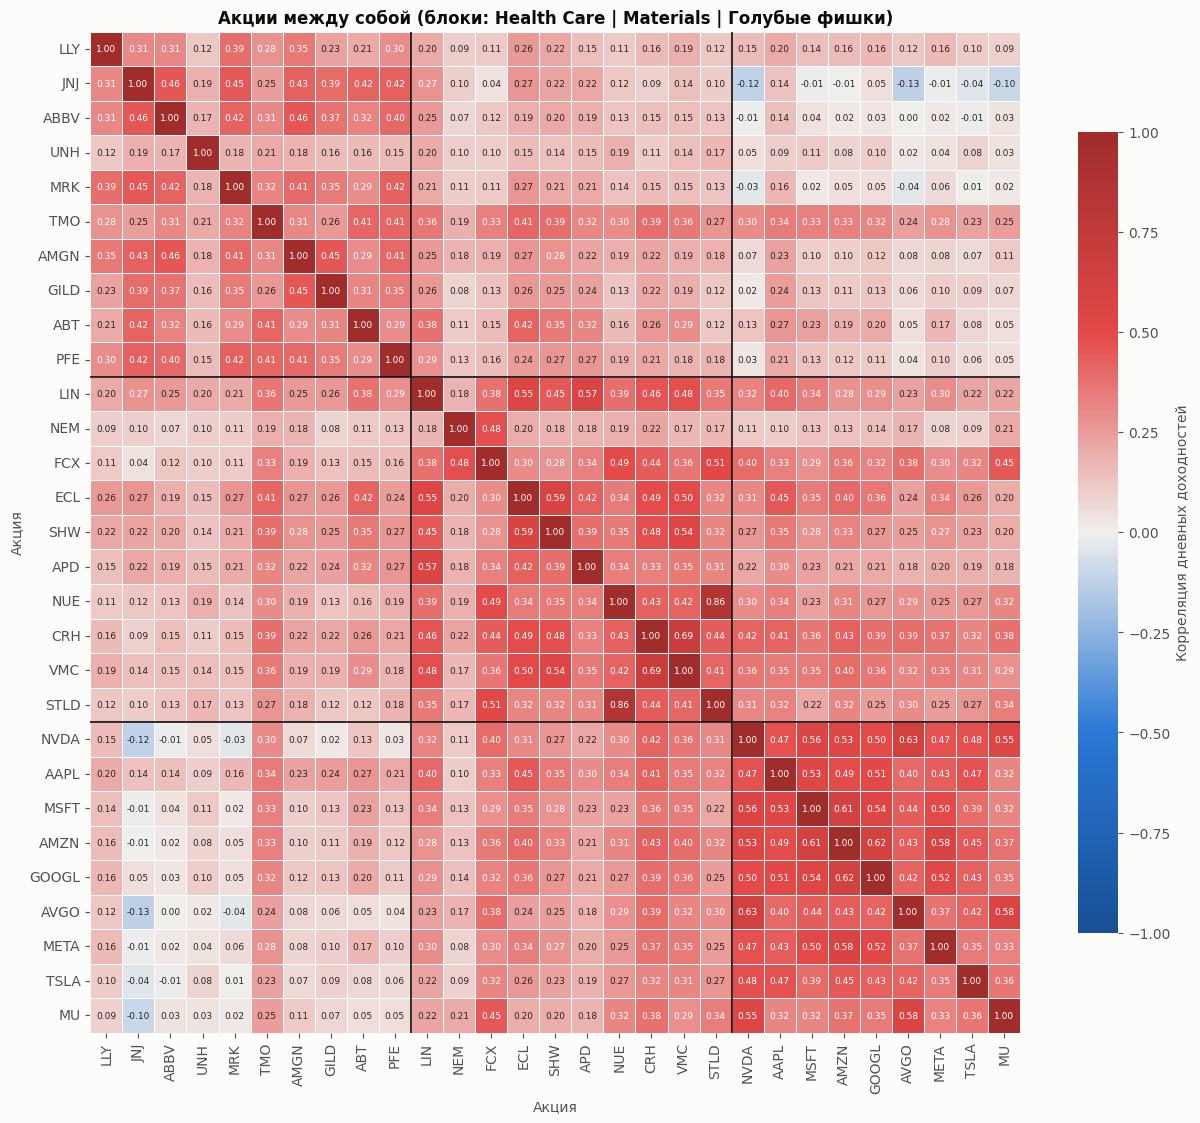

In [28]:
fig, ax = plt.subplots(figsize=(15, 13))
heatmap(ax, corr.loc[STOCKS, STOCKS], DIV, "Корреляция дневных доходностей", vmin=-1, vmax=1, center=0, annot_size=6.5)
group_lines(ax, STOCKS)
ax.set_xlabel("Акция"); ax.set_ylabel("Акция")
ax.set_title("Акции между собой (блоки: Health Care | Materials | Голубые фишки)")
plt.show()

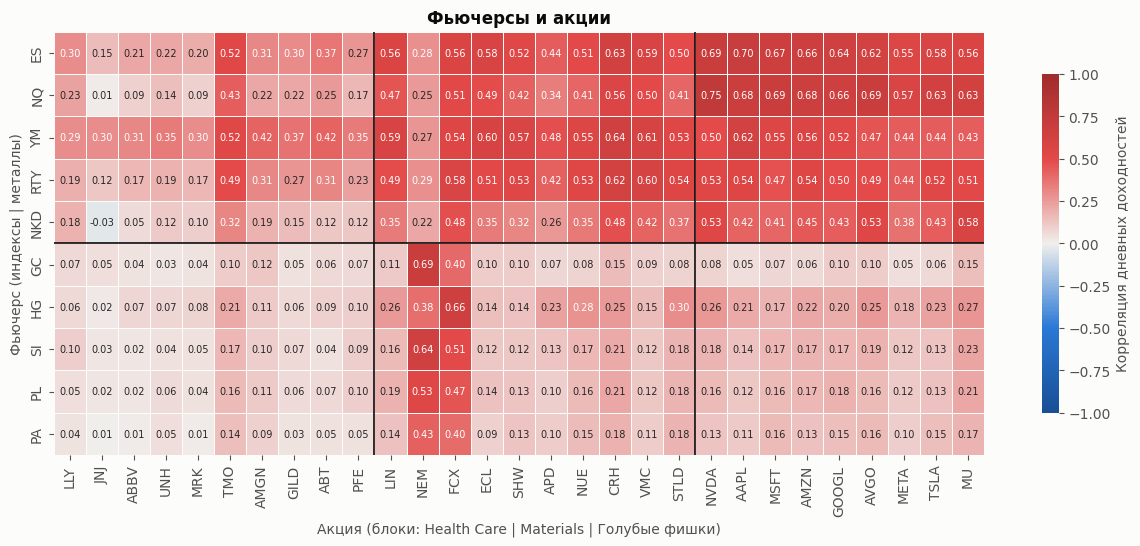

In [29]:
fig, ax = plt.subplots(figsize=(15, 5.5))
heatmap(ax, corr.loc[FUTURES, STOCKS], DIV, "Корреляция дневных доходностей", vmin=-1, vmax=1, center=0, annot_size=7)
group_lines(ax, STOCKS, horizontal=False)
ax.axhline(5, color=INK, lw=1.2)
ax.set_xlabel("Акция (блоки: Health Care | Materials | Голубые фишки)"); ax.set_ylabel("Фьючерс (индексы | металлы)")
ax.set_title("Фьючерсы и акции")
plt.show()

In [30]:
def block_mean(rows, cols):
    sub = corr.loc[rows, cols].to_numpy()
    if rows == cols:
        sub = sub[np.triu_indices_from(sub, k=1)]
    return float(np.nanmean(sub))

blocks = {}
for g in GROUP_IDS:
    blocks[f"{GROUP_NAME[g]} между собой"] = block_mean(members(g), members(g))
blocks["Фьючерсы на индексы и на металлы"] = block_mean(members("indices"), members("metals"))
for g in ["health_care", "materials", "blue_chips"]:
    blocks[f"Фьючерсы на индексы и {GROUP_NAME[g].lower()}"] = block_mean(members("indices"), members(g))
    blocks[f"Фьючерсы на металлы и {GROUP_NAME[g].lower()}"] = block_mean(members("metals"), members(g))
blocks["Health Care и Materials"] = block_mean(members("health_care"), members("materials"))
blocks["Health Care и голубые фишки"] = block_mean(members("health_care"), members("blue_chips"))
blocks["Materials и голубые фишки"] = block_mean(members("materials"), members("blue_chips"))
display(pd.Series(blocks, name="Средняя корреляция").to_frame())

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("Корреляция").reset_index()
pairs.columns = ["Инструмент 1", "Инструмент 2", "Корреляция"]
kind = lambda a, b: "фьючерс и фьючерс" if a in FUTURES and b in FUTURES else ("акция и акция" if a in STOCKS and b in STOCKS else "фьючерс и акция")
pairs["Тип пары"] = [kind(a, b) for a, b in zip(pairs["Инструмент 1"], pairs["Инструмент 2"])]
print("Самые связанные пары:")
display(pairs.sort_values("Корреляция", ascending=False).groupby("Тип пары").head(5).sort_values(["Тип пары", "Корреляция"], ascending=[True, False]).set_index("Тип пары"))
print("Самые независимые пары:")
display(pairs.sort_values("Корреляция").groupby("Тип пары").head(3).sort_values(["Тип пары", "Корреляция"]).set_index("Тип пары"))

,Средняя корреляция
Фьючерсы на индексы между собой,0.78
Фьючерсы на металлы между собой,0.58
Акции Health Care между собой,0.32
Акции Materials между собой,0.39
Голубые фишки между собой,0.46
Фьючерсы на индексы и на металлы,0.25
Фьючерсы на индексы и акции health care,0.24
Фьючерсы на металлы и акции health care,0.07
Фьючерсы на индексы и акции materials,0.47
Фьючерсы на металлы и акции materials,0.22


Самые связанные пары:


,Инструмент 1,Инструмент 2,Корреляция
Тип пары,,,
акция и акция,NUE,STLD,0.86
акция и акция,CRH,VMC,0.69
акция и акция,NVDA,AVGO,0.63
акция и акция,AMZN,GOOGL,0.62
акция и акция,MSFT,AMZN,0.61
фьючерс и акция,NQ,NVDA,0.75
фьючерс и акция,ES,AAPL,0.70
фьючерс и акция,GC,NEM,0.69
фьючерс и акция,NQ,MSFT,0.69


Самые независимые пары:


,Инструмент 1,Инструмент 2,Корреляция
Тип пары,,,
акция и акция,JNJ,AVGO,-0.13
акция и акция,JNJ,NVDA,-0.12
акция и акция,JNJ,MU,-0.10
фьючерс и акция,NKD,JNJ,-0.03
фьючерс и акция,PA,JNJ,0.01
фьючерс и акция,PA,MRK,0.01
фьючерс и фьючерс,NKD,GC,0.14
фьючерс и фьючерс,NQ,GC,0.14
фьючерс и фьючерс,YM,GC,0.15


#### Вывод по разделу 5

- **Фьючерсы на индексы США — практически один актив.**
    - Корреляция ES и NQ — 0.95, ES и YM — 0.91, ES и RTY — 0.85.
    - Японский Nikkei (NKD) связан с ними слабее, но средняя корреляция по группе всё равно 0.78.
- **Металлы связаны умеренно** (в среднем 0.58). Сильнее всего золото и серебро (0.79). С индексами металлы почти не связаны (0.25), золото — меньше всех (0.14–0.15 с NQ, YM и NKD): классическая роль «тихой гавани».
- **Акции в среднем связаны слабо: у каждой компании много собственного риска.**
    - Внутри секторов связь сильнее: голубые фишки 0.46, Materials 0.39, Health Care 0.32.
    - Между секторами связь слабая: Health Care и голубые фишки — всего 0.10.
    - Самые связанные пары — компании одной отрасли: сталелитейщики NUE и STLD (0.86), производители стройматериалов CRH и VMC (0.69), полупроводники NVDA и AVGO (0.63), AMZN и GOOGL (0.62).
    - Johnson & Johnson слегка отрицательно связан с полупроводниками (до −0.13) — типичная защитная акция.
- **Фьючерсы и акции.**
    - Голубые фишки сильно связаны с фьючерсами на индексы (в среднем 0.55; NQ и NVDA — 0.75, ES и AAPL — 0.70): крупнейшие компании сами составляют значительную часть индексов.
    - Materials связаны с индексами на 0.47, Health Care — только на 0.24.
    - С металлами сильно связаны только добывающие компании: золото и Newmont (GC и NEM) — 0.69, медь и Freeport-McMoRan (HG и FCX) — 0.66.

**Что это значит для проекта.** Выходы из консолидации у ES, NQ, YM и RTY почти всегда происходят в одни и те же дни: для модели это не четыре независимых примера, а один, повторённый четыре раза. Данные для обучения и проверки моделей нужно делить по времени, а не случайным образом, иначе один и тот же рыночный день окажется и в обучающей, и в тестовой выборке через разные инструменты. Движение индекса или сектора в момент выхода из консолидации — хороший кандидат в признаки для акций.

## 6. Как менялись ATR и STD во времени

**Вопрос.** Как волатильность менялась за пять лет, совпадают ли периоды высокой волатильности у разных инструментов и насколько похожи между собой ATR и STD?

**Как считали.** Сравниваем ATR и STD в процентах от цены (см. раздел 1). Связь между ними меряем двумя способами:
- **корреляция уровней** — насколько совпадают периоды высокой и низкой волатильности по двум показателям;
- **корреляция ежедневных изменений** — насколько синхронно оба показателя реагируют на каждый новый день.

Ещё смотрим **отношение ATR к STD**: во сколько раз средний дневной диапазон цены больше типичного изменения цены закрытия.

**На графиках для каждой группы:** динамика ATR (синяя линия) и STD (оранжевая) по каждому инструменту, средняя ATR по группе и тепловая карта медианной ATR по годам.

In [31]:
def vol_stats(d):
    x = d[["atr_30_pct", "std_30_pct"]].dropna()
    return pd.Series({
        "Корреляция уровней": x["atr_30_pct"].corr(x["std_30_pct"]),
        "Корреляция изменений": x["atr_30_pct"].diff().corr(x["std_30_pct"].diff()),
        "ATR / STD (медиана)": (x["atr_30_pct"] / x["std_30_pct"]).median(),
        "ATR, % мин": x["atr_30_pct"].min(), "ATR, % медиана": x["atr_30_pct"].median(), "ATR, % макс": x["atr_30_pct"].max(),
        "Дата максимума ATR": d.loc[d["atr_30_pct"].idxmax(), "trade_date"].strftime("%d.%m.%Y"),
    })
vol_table = pd.DataFrame({t: vol_stats(d) for t, d in daily.items()}).T
num_cols = [c for c in vol_table.columns if c != "Дата максимума ATR"]
vol_table[num_cols] = vol_table[num_cols].astype(float)
yearly_atr = panel.assign(year=panel["trade_date"].dt.year).groupby(["ticker", "year"])["atr_30_pct"].median().unstack().drop(columns=[2021])

def atr_report(group):
    tick = members(group)
    ncols = 5; nrows = int(np.ceil(len(tick) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(17, 2.7 * nrows + 0.6), sharex=True, squeeze=False)
    for ax, t in zip(axes.flat, tick):
        d = daily[t]
        ax.plot(d["trade_date"], d["atr_30_pct"], color=CAT[0], lw=1.3, label="ATR 30")
        ax.plot(d["trade_date"], d["std_30_pct"], color=CAT[1], lw=1.3, label="STD 30")
        ax.set_title(t, fontsize=11); ax.tick_params(labelsize=8)
        ax.set_ylabel("% от цены", fontsize=8)
    for ax in axes[-1]:
        ax.set_xlabel("Дата", fontsize=8)
    for ax in list(axes.flat)[len(tick):]:
        ax.axis("off")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", ncol=2)
    fig.suptitle(f"{GROUP_NAME[group]}: ATR 30 и STD 30, % от цены", x=0.01, ha="left", fontweight="bold", fontsize=13)
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(16, max(3.6, 0.42 * len(tick) + 1.6)), gridspec_kw={"width_ratios": [1.5, 1]})
    ax = axes[0]
    sub = panel[panel["ticker"].isin(tick)]
    full_days = sub.groupby("trade_date")["ticker"].transform("count") == len(tick)
    mean_line = sub[full_days].groupby("trade_date")[["atr_30_pct", "std_30_pct"]].mean()
    ax.plot(mean_line.index, mean_line["atr_30_pct"], color=CAT[0], label="ATR 30")
    ax.plot(mean_line.index, mean_line["std_30_pct"], color=CAT[1], label="STD 30")
    ax.set_xlabel("Дата"); ax.set_ylabel("% от цены"); ax.legend(loc="upper left")
    ax.set_title("Среднее по инструментам группы")
    heatmap(axes[1], yearly_atr.loc[tick], SEQ, "Медиана ATR 30, % от цены", annot_size=8)
    axes[1].set_xlabel("Год"); axes[1].set_ylabel("Инструмент"); axes[1].set_title("Медиана ATR 30 по годам, % (2026 — январь–сентябрь)")
    plt.tight_layout(); plt.show()
    display(vol_table.loc[tick])

### Фьючерсы на фондовые индексы

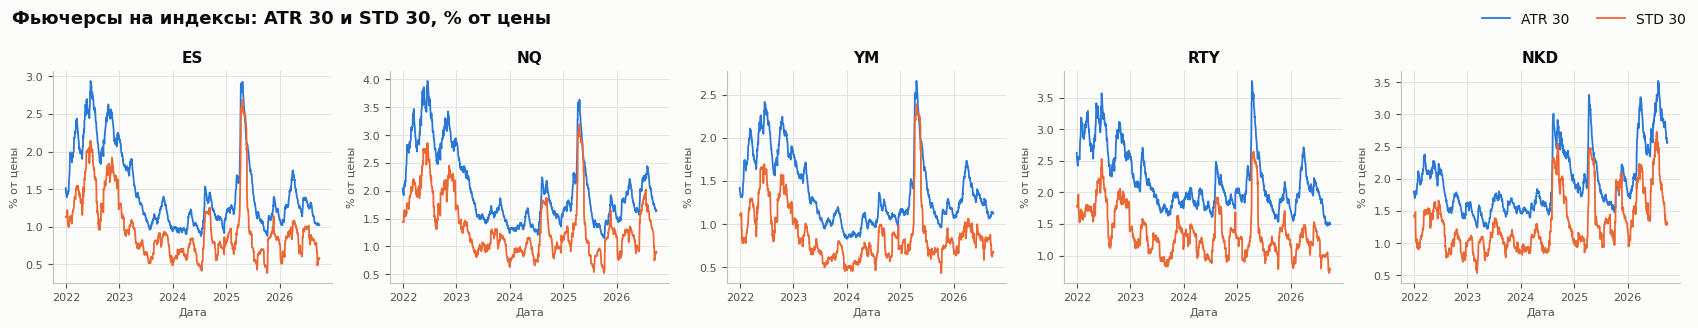

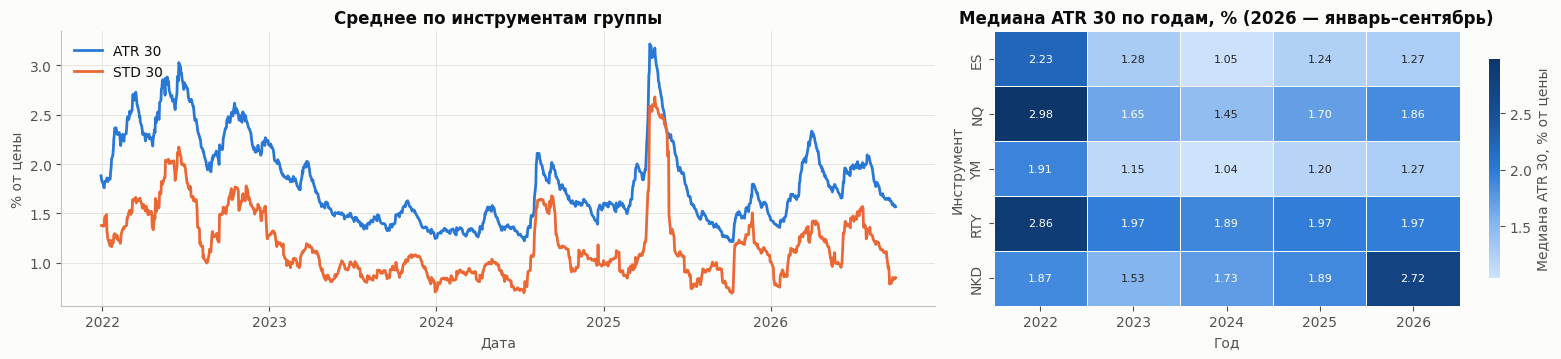

,Корреляция уровней,Корреляция изменений,ATR / STD (медиана),"ATR, % мин","ATR, % медиана","ATR, % макс",Дата максимума ATR
ES,0.92,0.54,1.53,0.88,1.29,2.94,17.06.2022
NQ,0.92,0.56,1.52,1.15,1.80,3.97,17.06.2022
YM,0.90,0.53,1.59,0.83,1.24,2.66,22.04.2025
RTY,0.85,0.51,1.63,1.47,2.03,3.77,11.04.2025
NKD,0.87,0.61,1.52,1.22,1.78,3.52,30.07.2026


In [32]:
atr_report("indices")

### Фьючерсы на металлы

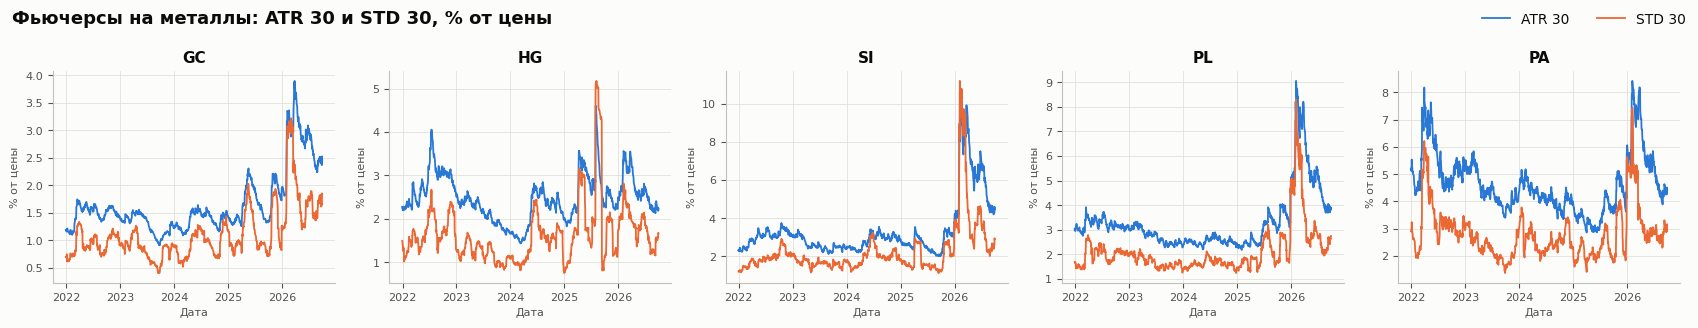

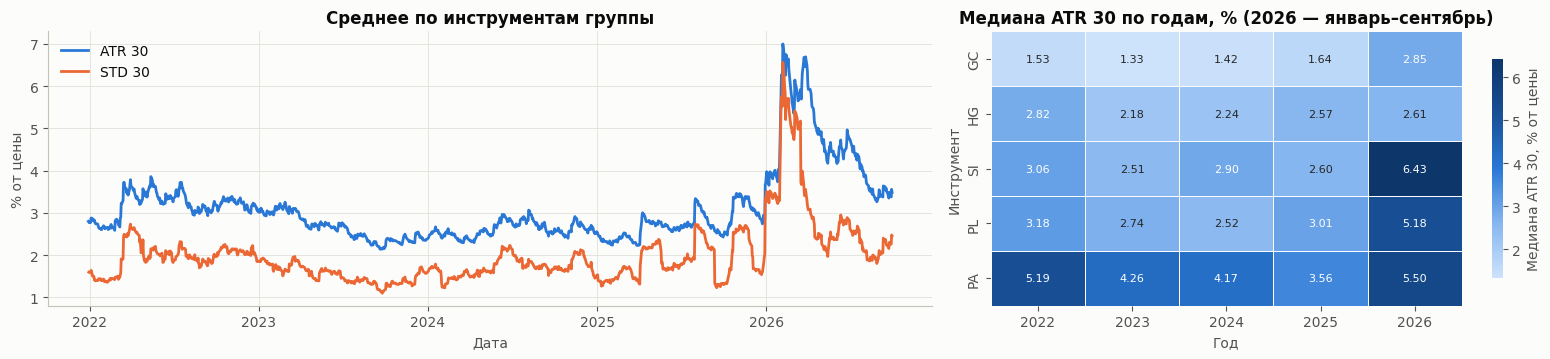

,Корреляция уровней,Корреляция изменений,ATR / STD (медиана),"ATR, % мин","ATR, % медиана","ATR, % макс",Дата максимума ATR
GC,0.87,0.70,1.56,0.91,1.48,3.90,27.03.2026
HG,0.76,0.63,1.59,1.43,2.43,4.61,01.08.2025
SI,0.86,0.80,1.57,2.00,2.93,10.62,06.02.2026
PL,0.88,0.81,1.58,2.18,2.99,9.05,06.02.2026
PA,0.80,0.73,1.73,2.86,4.40,8.42,06.02.2026


In [33]:
atr_report("metals")

### Акции сектора Health Care (здравоохранение)

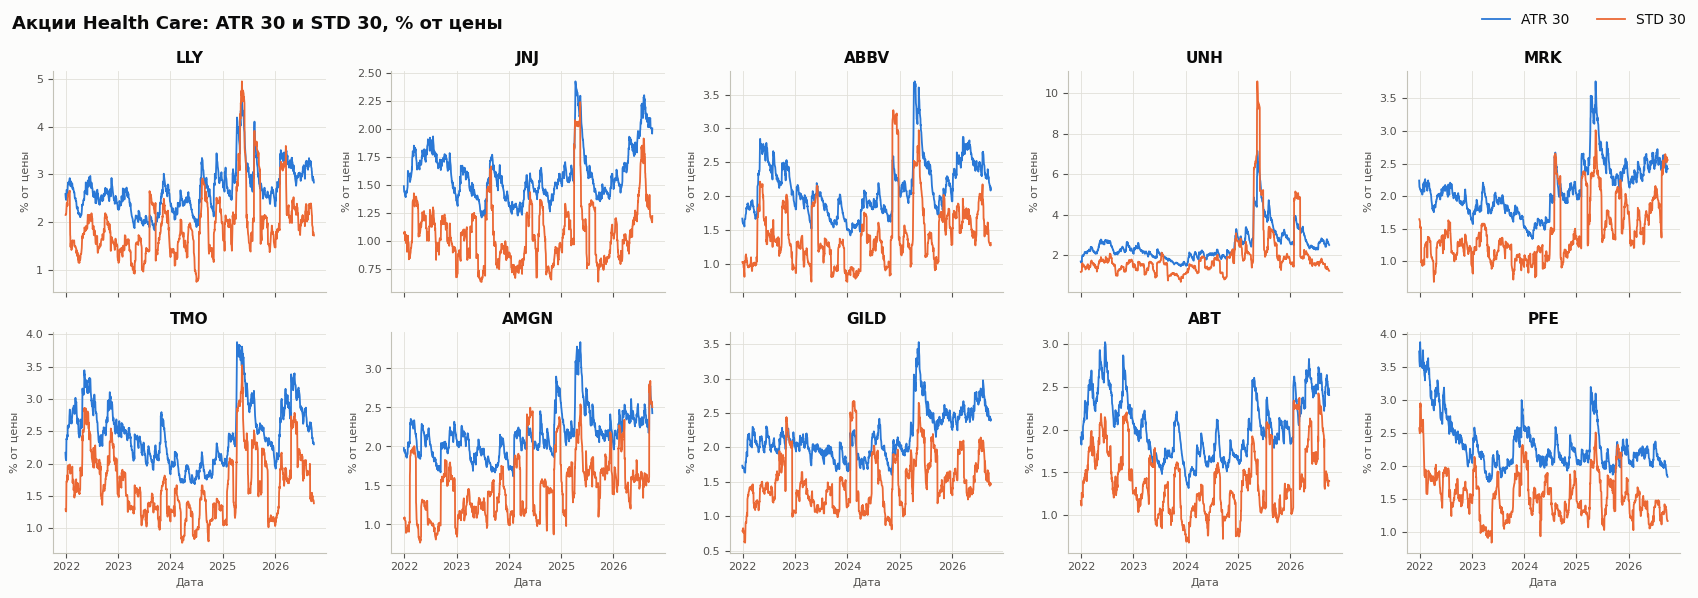

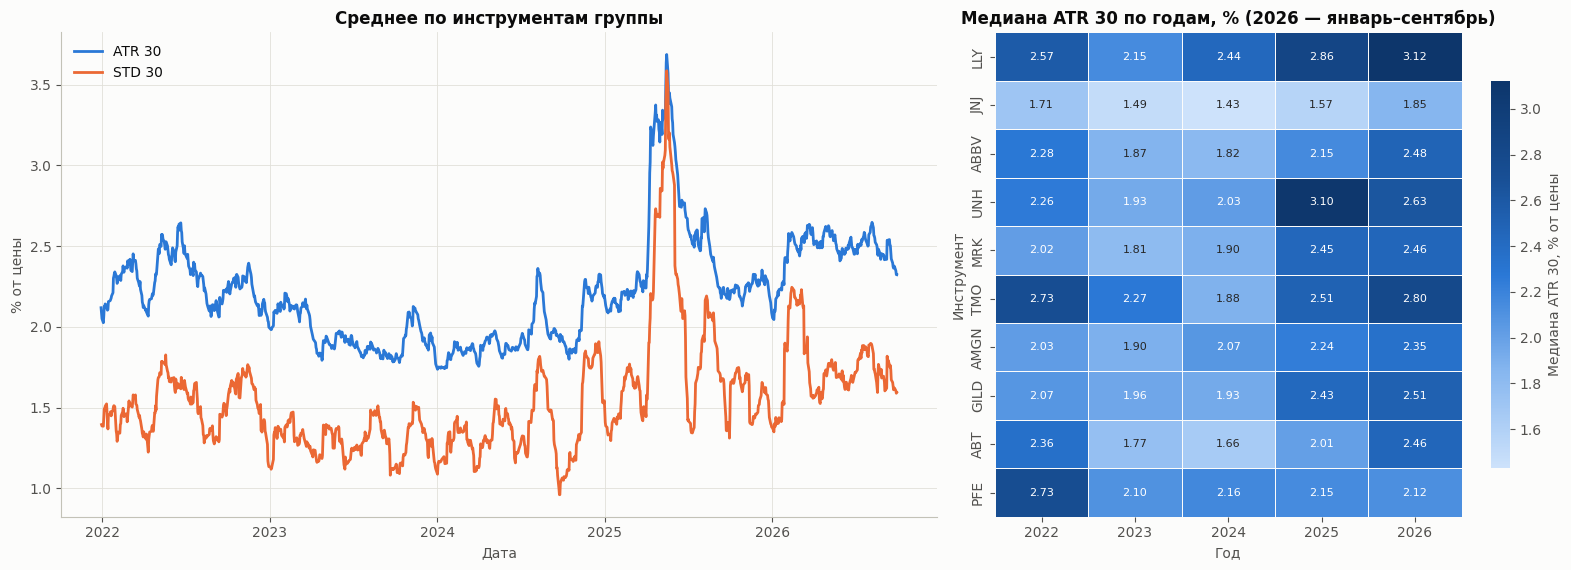

,Корреляция уровней,Корреляция изменений,ATR / STD (медиана),"ATR, % мин","ATR, % медиана","ATR, % макс",Дата максимума ATR
LLY,0.80,0.61,1.44,1.82,2.62,4.64,15.05.2025
JNJ,0.78,0.56,1.57,1.21,1.56,2.42,11.04.2025
ABBV,0.71,0.64,1.59,1.42,2.04,3.70,17.04.2025
UNH,0.87,0.69,1.46,1.44,2.28,7.15,16.05.2025
MRK,0.80,0.58,1.51,1.34,2.05,3.76,15.05.2025
TMO,0.88,0.55,1.50,1.68,2.43,3.88,11.04.2025
AMGN,0.69,0.62,1.47,1.62,2.13,3.34,15.05.2025
GILD,0.62,0.51,1.52,1.60,2.09,3.53,15.05.2025
ABT,0.81,0.58,1.48,1.32,2.02,3.02,17.06.2022
PFE,0.69,0.59,1.51,1.76,2.19,3.88,05.01.2022


In [34]:
atr_report("health_care")

### Акции сектора Materials (сырьё и материалы)

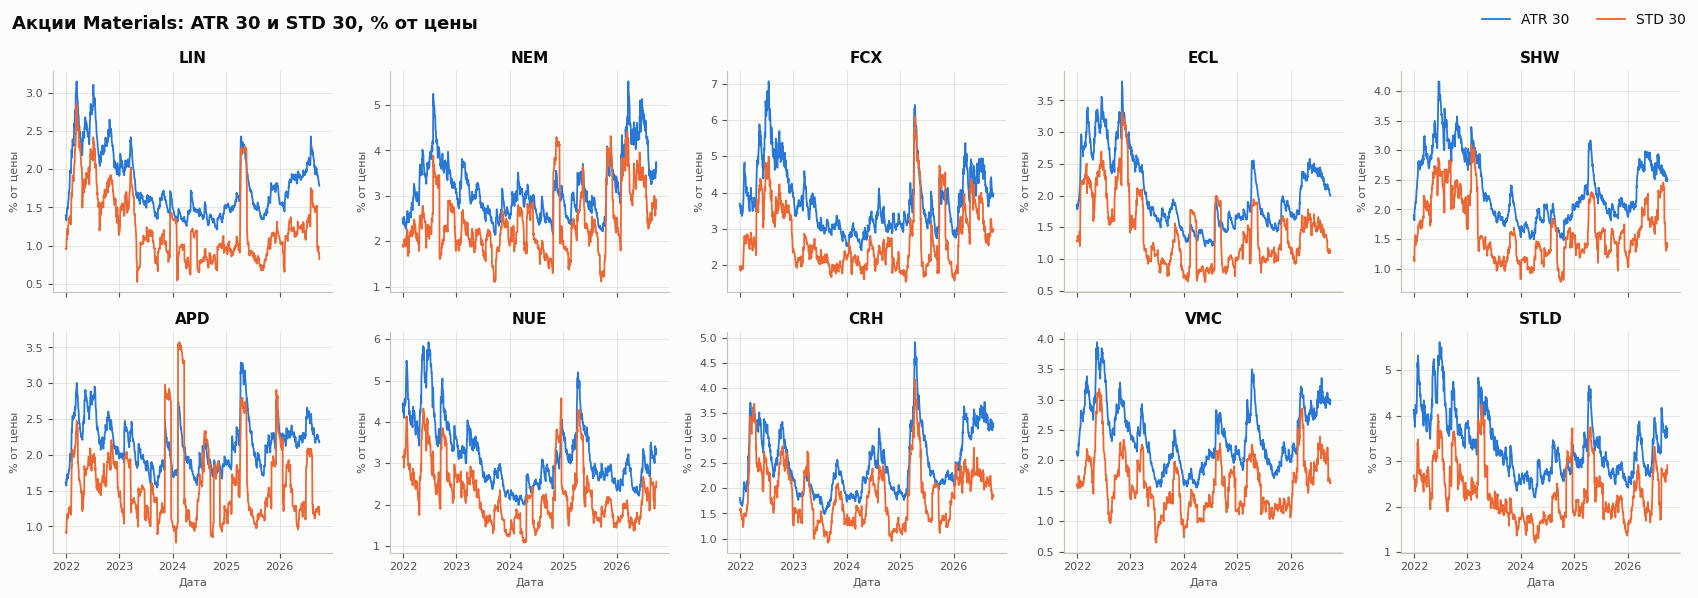

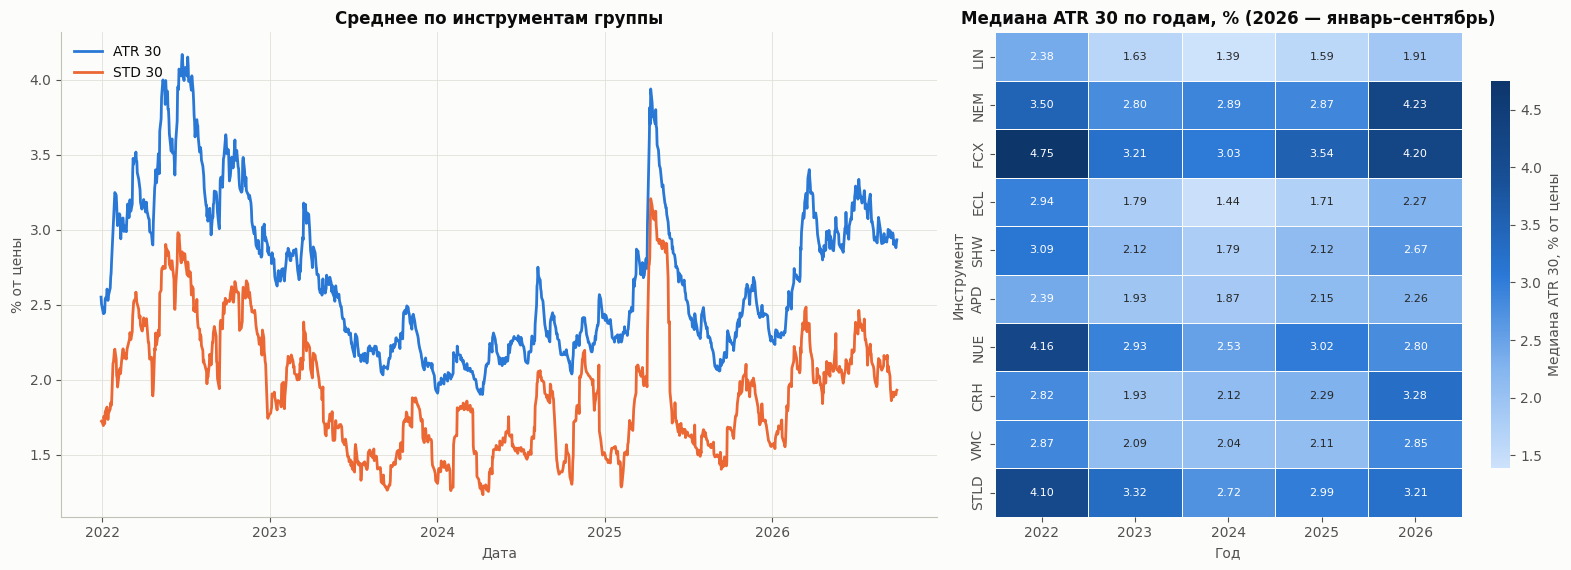

,Корреляция уровней,Корреляция изменений,ATR / STD (медиана),"ATR, % мин","ATR, % медиана","ATR, % макс",Дата максимума ATR
LIN,0.92,0.62,1.49,1.21,1.67,3.15,14.03.2022
NEM,0.76,0.66,1.36,2.14,3.04,5.52,23.03.2026
FCX,0.85,0.73,1.43,2.40,3.61,7.07,15.07.2022
ECL,0.87,0.56,1.50,1.20,1.82,3.80,04.11.2022
SHW,0.89,0.58,1.46,1.48,2.18,4.16,17.06.2022
APD,0.59,0.61,1.45,1.54,2.13,3.29,11.04.2025
NUE,0.86,0.63,1.47,1.99,2.98,5.93,24.06.2022
CRH,0.85,0.62,1.33,1.49,2.33,4.91,11.04.2025
VMC,0.86,0.60,1.50,1.55,2.30,3.95,17.05.2022
STLD,0.82,0.63,1.50,2.20,3.23,5.62,24.06.2022


In [35]:
atr_report("materials")

### Голубые фишки

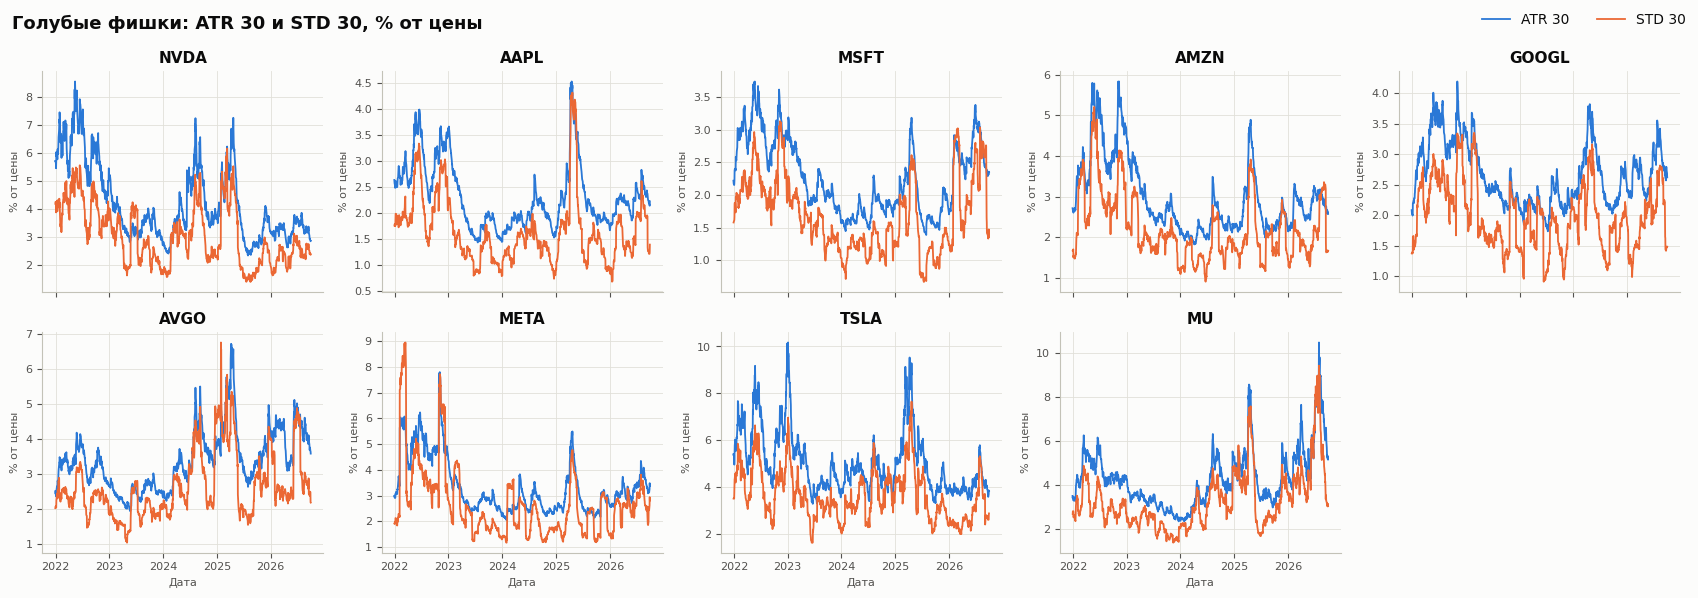

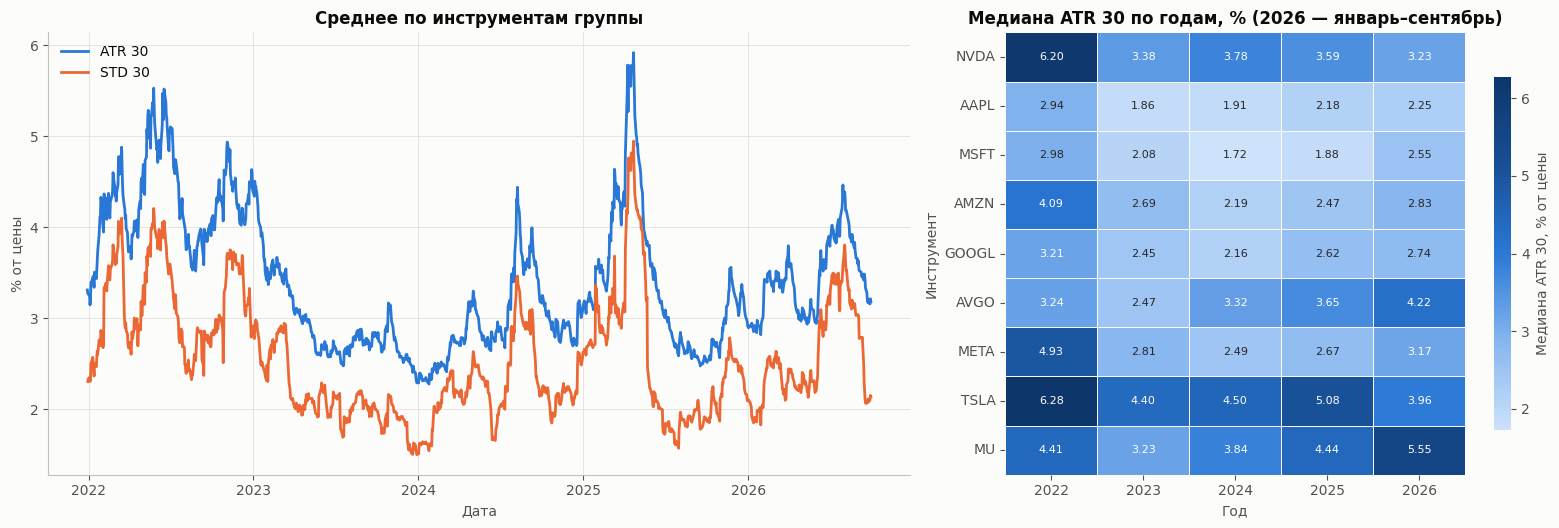

,Корреляция уровней,Корреляция изменений,ATR / STD (медиана),"ATR, % мин","ATR, % медиана","ATR, % макс",Дата максимума ATR
NVDA,0.87,0.64,1.42,2.34,3.72,8.57,13.05.2022
AAPL,0.90,0.62,1.45,1.43,2.19,4.52,17.04.2025
MSFT,0.89,0.57,1.39,1.39,2.17,3.74,23.05.2022
AMZN,0.88,0.59,1.41,1.82,2.70,5.83,10.11.2022
GOOGL,0.80,0.61,1.38,1.74,2.59,4.19,04.11.2022
AVGO,0.82,0.66,1.35,1.94,3.29,6.71,07.04.2025
META,0.84,0.66,1.40,2.04,2.97,7.79,03.11.2022
TSLA,0.88,0.77,1.42,3.30,4.73,10.17,04.01.2023
MU,0.92,0.81,1.33,2.37,4.14,10.47,30.07.2026


In [36]:
atr_report("blue_chips")

#### Вывод по разделу 6

**Периоды высокой волатильности общие для всего рынка:**
- **2022 год** — затяжное падение рынка и повышение ставок ФРС. У индексов, голубых фишек и Materials ATR повышен весь год, у многих инструментов максимум за пять лет пришёлся на май–июль 2022 года (ES, NQ — 17.06.2022; NVDA, MSFT — май; NUE, STLD, FCX — июнь–июль). Осенью 2022 года отдельные пики у голубых фишек (AMZN, GOOGL, META — начало ноября) после слабых квартальных отчётов.
- **2023 — середина 2024 года** — самый спокойный период: волатильность у всех групп на минимуме.
- **Апрель 2025 года** — резкий всплеск сразу во всех группах, особенно у фьючерсов на индексы и акций (YM, RTY, JNJ, TMO, AAPL, AVGO, APD, CRH — максимум 7–22 апреля 2025 года). По времени совпадает с объявлением новых импортных пошлин США в начале апреля 2025 года.
- **Health Care, май 2025 года** — у LLY, MRK, AMGN, GILD и UNH максимум ATR пришёлся на 15–16 мая. У UnitedHealth (UNH) ATR вырос до 7.2% от цены — втрое выше обычного уровня; это событие самой компании. Совпадение дат у фармкомпаний указывает на общие новости сектора; причины мы не исследовали.
- **Металлы, январь–февраль 2026 года** — исключительный всплеск: серебро до 10.6% в день, платина до 9.0%, палладий до 8.4% (максимум у всех трёх — 6 февраля 2026 года). На этот же период пришёлся рекордный объём (раздел 2). С металлами двигались и добывающие компании: у Newmont (NEM) максимум ATR — в марте 2026 года.

**ATR и STD:**
- **Синхронны в длинных периодах.** Корреляция уровней — от 0.59 до 0.92, у большинства инструментов выше 0.8. Корреляция ежедневных изменений заметно ниже — 0.51–0.81.
- **По-разному реагируют на отдельные дни.**
    - STD реагирует на шоковые дни резко: один день с большим движением сразу поднимает показатель, а ровно через 30 дней этот день выпадает из окна, и STD так же резко падает. На графиках это видно как «ступеньки» оранжевой линии.
    - ATR меняется плавно благодаря сглаживанию Уайлдера.
- **У металлов ATR и STD связаны сильнее всего** (изменения коррелируют на 0.63–0.81): движения металлов более «гладкие», с меньшим количеством разрывов между днями.

**Что это значит для проекта.**
- Для индикатора консолидации лучшей базой выглядит ATR в процентах от цены: он устойчив и не даёт ложных скачков. STD полезен как дополнительный сигнал резких шоков.
- Естественное продолжение этой работы — признак сжатия волатильности: отношение ATR за короткий период к ATR за длинный. Консолидация — как раз период, когда короткая волатильность опускается ниже долгосрочной.
- Порог «консолидации» нельзя задавать одним числом на все пять лет: минимальный и максимальный ATR одного инструмента за пять лет различаются в 2–5 раз. Порог нужно считать относительно текущего режима.

## 7. Сильные движения: когда цена уходит от открытия дальше ATR и STD

**Вопрос.** Как часто за день цена уходит от цены открытия дальше своей обычной дневной амплитуды? И в какую сторону закрывается такой день — вверх (Long) или вниз (Short)?

Этот вопрос близок к главной задаче проекта: выход из консолидации — это как раз момент, когда цена сильно уходит от сложившегося уровня, и нам важно понимать, как часто это бывает и чем заканчивается.

**Как считали.**
- **Отклонение вверх** — насколько максимум дня выше цены открытия (High − Open). **Отклонение вниз** — насколько минимум дня ниже открытия (Open − Low). **Максимальное отклонение** — большее из двух.
- **Порог** — ATR или STD, известные утром этого дня (посчитанные по вчерашний день включительно).
- **Сильный день (выброс)** — день, когда отклонение больше порога. Считаем отдельно: максимальное отклонение (в любую сторону), только вверх и только вниз.
- **Направление закрытия:** Long — цена закрытия выше открытия, Short — ниже. **Доля Long** — Long / (Long + Short) × 100%. 50% — направления встречаются одинаково часто.
- 2021 год не берём: ATR и STD появляются только в конце декабря 2021 года, когда накопилось 30 дней истории. 2026 год в данных — с января по сентябрь, поэтому кроме количества дней в году смотрим на **частоту** — долю таких дней в процентах.

**На графиках для каждой группы:** частота сильных движений вверх и вниз по инструментам (для порога ATR и порога STD) и доля дней, закрытых в Long: среди выходов вверх, среди выходов вниз и среди всех дней — для сравнения.

In [37]:
rows = []
for t, d in daily.items():
    x = d.dropna(subset=["atr_30", "std_30"])
    x = x[x["trade_date"].dt.year >= 2022]
    up, down = x["real_high"] - x["real_open"], x["real_open"] - x["real_low"]
    long_, short_ = x["real_close"] > x["real_open"], x["real_close"] < x["real_open"]
    for thr in ["atr_30", "std_30"]:
        for kind, flag in {"max": np.maximum(up, down) > x[thr], "up": up > x[thr], "down": down > x[thr]}.items():
            for year, idx in x.groupby(x["trade_date"].dt.year).groups.items():
                f = flag.loc[idx]
                rows.append({"ticker": t, "group": GROUP[t], "threshold": "ATR" if thr == "atr_30" else "STD", "kind": kind,
                             "year": year, "days": len(idx), "events": int(f.sum()),
                             "long": int((f & long_.loc[idx]).sum()), "short": int((f & short_.loc[idx]).sum()),
                             "all_long": int(long_.loc[idx].sum()), "all_short": int(short_.loc[idx].sum())})
ev = pd.DataFrame(rows)

def summary(frame):
    s = frame.groupby(["threshold", "kind"])[["days", "events", "long", "short", "all_long", "all_short"]].sum()
    s["freq"] = s["events"] / s["days"] * 100
    s["long_share"] = s["long"] / (s["long"] + s["short"]) * 100
    s["base_long_share"] = s["all_long"] / (s["all_long"] + s["all_short"]) * 100
    return s

KIND = {"max": "в любую сторону", "up": "вверх", "down": "вниз"}

def outlier_report(group):
    tick = members(group)
    e = ev[ev["ticker"].isin(tick)]
    by_inst = {t: summary(e[e["ticker"] == t]) for t in tick}
    freq = pd.DataFrame({t: s["freq"] for t, s in by_inst.items()}).T
    share = pd.DataFrame({t: s["long_share"] for t, s in by_inst.items()}).T
    base = pd.Series({t: s["base_long_share"].iloc[0] for t, s in by_inst.items()})

    fig, axes = plt.subplots(1, 2, figsize=(16, 4))
    x = np.arange(len(tick)); w = 0.4
    for ax, thr in zip(axes, ["ATR", "STD"]):
        ax.bar(x - w / 2, freq[(thr, "up")], w - 0.04, color=CAT[0], label="вверх: High − Open > порога")
        ax.bar(x + w / 2, freq[(thr, "down")], w - 0.04, color=CAT[1], label="вниз: Open − Low > порога")
        ax.set_xticks(x, tick); ax.set_xlabel("Инструмент"); ax.set_ylabel("Доля дней, %")
        ax.set_title(f"Порог — {thr} 30"); ax.legend(loc="upper left")
        ax.set_ylim(0, freq[(thr, "up")].max() * 1.35 if thr == "ATR" else max(freq[(thr, "up")].max(), freq[(thr, "down")].max()) * 1.35)
    fig.suptitle(f"{GROUP_NAME[group]}: как часто цена уходит от открытия дальше порога", x=0.01, ha="left", fontweight="bold", fontsize=13)
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(16, 4))
    ax.axhline(50, color=INK2, lw=1, ls="--")
    ax.plot(x, share[("ATR", "up")], "o", color=CAT[0], ms=9, label="дни с выходом вверх за ATR")
    ax.plot(x, share[("ATR", "down")], "o", color=CAT[1], ms=9, label="дни с выходом вниз за ATR")
    ax.plot(x, share[("ATR", "max")], "D", color=CAT[2], ms=7, label="все дни с выходом за ATR")
    ax.plot(x, base.loc[tick], "_", color=INK, ms=18, mew=2, label="все дни")
    ax.set_xticks(x, tick); ax.set_ylim(-5, 105)
    ax.set_xlabel("Инструмент"); ax.set_ylabel("Доля дней, закрытых в Long, %")
    ax.set_title(f"{GROUP_NAME[group]}: в какую сторону закрываются дни с сильным движением")
    ax.legend(ncol=2, loc="center left", bbox_to_anchor=(0.01, 0.22))
    plt.tight_layout(); plt.show()

    for thr in ["ATR", "STD"]:
        t = e[(e["threshold"] == thr) & (e["kind"] == "max")].pivot(index="ticker", columns="year", values="events").loc[tick]
        t.columns = [str(c) for c in t.columns]
        t["В среднем за год (2022–2025)"] = t[[str(y) for y in FULL_YEARS]].mean(axis=1)
        t["Доля дней, %"] = freq[(thr, "max")]
        t["Long"] = [by_inst[k].loc[(thr, "max"), "long"] for k in tick]
        t["Short"] = [by_inst[k].loc[(thr, "max"), "short"] for k in tick]
        t["Доля Long, %"] = share[(thr, "max")]
        t["Доля Long при выходе вверх, %"] = share[(thr, "up")]
        t["Доля Long при выходе вниз, %"] = share[(thr, "down")]
        t.index.name = None
        print(f"\nПорог {thr} 30: количество дней в году, когда цена ушла от открытия дальше порога (2026 — январь–сентябрь), и направление закрытия")
        display(t)

    g = summary(e)
    print(f"\nВся группа, 2022–2026: доля дней с сильным движением и доля Long")
    display(pd.DataFrame({
        "Доля дней, %": g["freq"], "Long": g["long"], "Short": g["short"], "Доля Long, %": g["long_share"],
    }).rename(index=KIND, level=1).round(1))
    print(f"Доля Long среди всех дней группы: {g['base_long_share'].iloc[0]:.1f}%")

### Фьючерсы на фондовые индексы

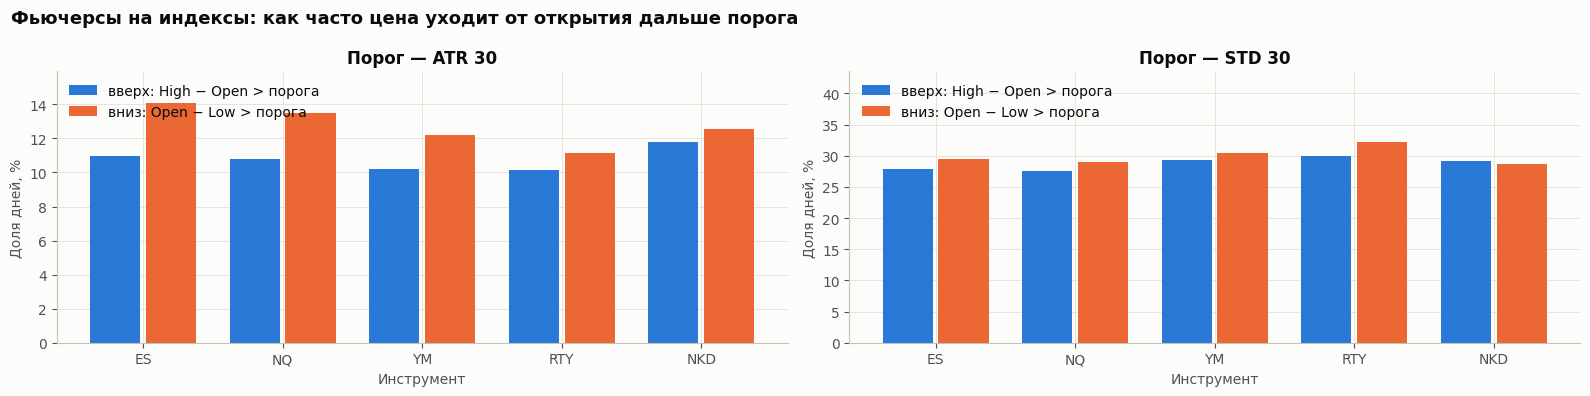

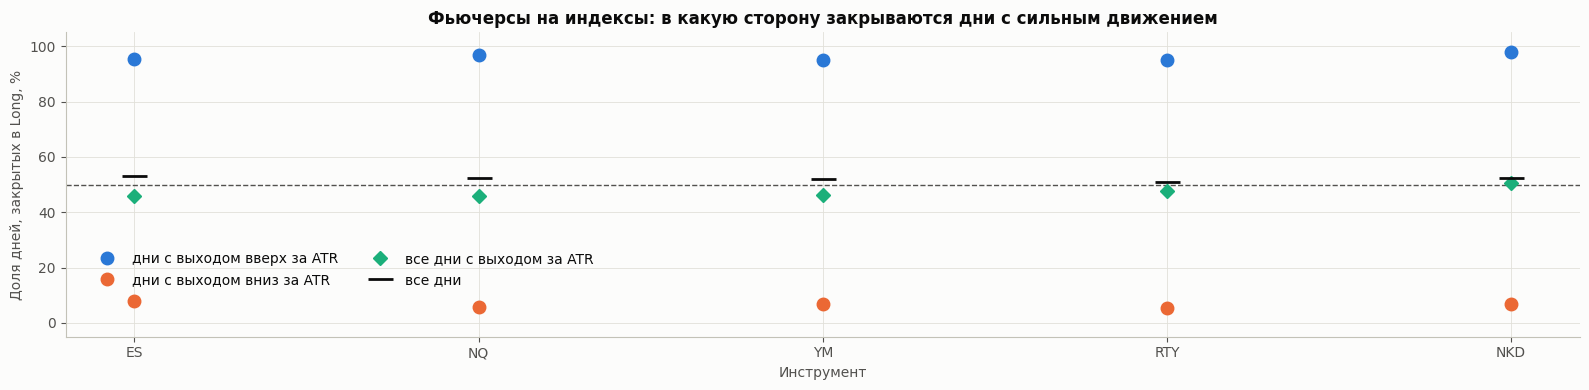


Порог ATR 30: количество дней в году, когда цена ушла от открытия дальше порога (2026 — январь–сентябрь), и направление закрытия


,2022,2023,2024,2025,2026,В среднем за год (2022–2025),"Доля дней, %",Long,Short,"Доля Long, %","Доля Long при выходе вверх, %","Доля Long при выходе вниз, %"
ES,56,51,74,62,48,60.75,24.37,133,158,45.70,95.42,7.74
NQ,53,53,73,57,49,59.00,23.87,131,154,45.96,96.90,5.59
YM,52,43,69,52,47,54.00,22.03,122,141,46.39,95.08,6.85
RTY,51,46,58,55,40,52.50,20.94,119,131,47.60,95.04,5.26
NKD,49,66,63,62,47,60.00,24.04,145,142,50.52,97.87,6.67



Порог STD 30: количество дней в году, когда цена ушла от открытия дальше порога (2026 — январь–сентябрь), и направление закрытия


,2022,2023,2024,2025,2026,В среднем за год (2022–2025),"Доля дней, %",Long,Short,"Доля Long, %","Доля Long при выходе вверх, %","Доля Long при выходе вниз, %"
ES,132,148,135,136,98,137.75,54.36,330,319,50.85,89.76,13.68
NQ,129,141,135,135,111,135.00,54.52,329,322,50.54,92.38,11.53
YM,144,135,150,139,114,142.00,57.12,339,341,49.85,91.09,11.02
RTY,141,164,141,138,120,146.00,58.96,346,358,49.15,89.92,11.95
NKD,141,138,146,119,117,136.00,55.36,331,329,50.15,89.91,10.50



Вся группа, 2022–2026: доля дней с сильным движением и доля Long


Доля дней, %  Long  Short  Доля Long, %
threshold kind                                                    
ATR       вниз                    12.70    49    709          6.50
          в любую сторону         23.00   650    726         47.20
          вверх                   10.80   619     25         96.10
STD       вниз                    30.00   210   1579         11.70
          в любую сторону         56.10  1675   1669         50.10
          вверх                   28.70  1551    161         90.60

Доля Long среди всех дней группы: 52.2%


In [38]:
outlier_report("indices")

### Фьючерсы на металлы

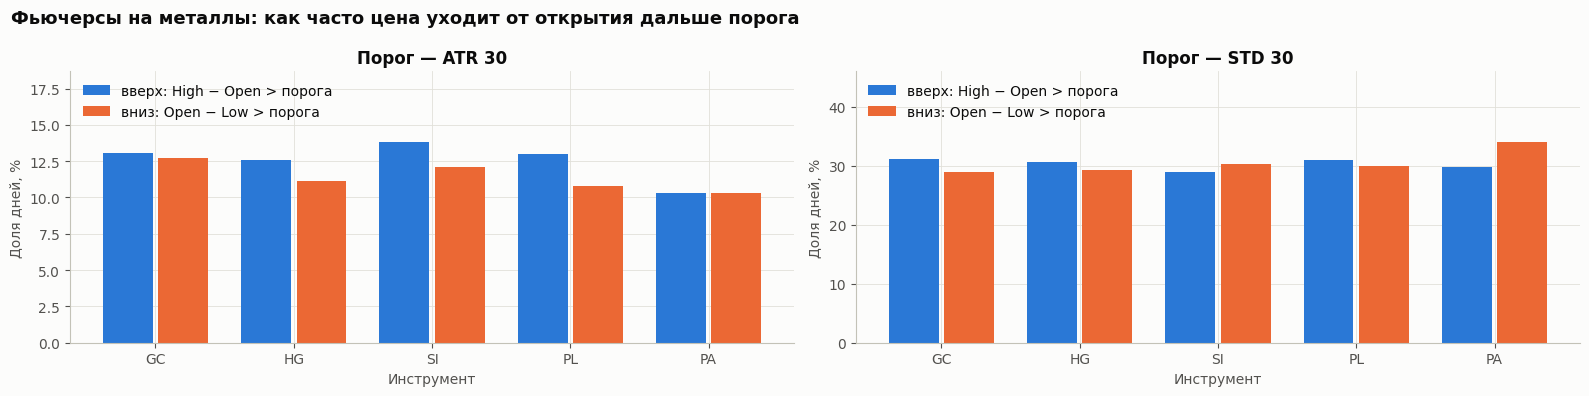

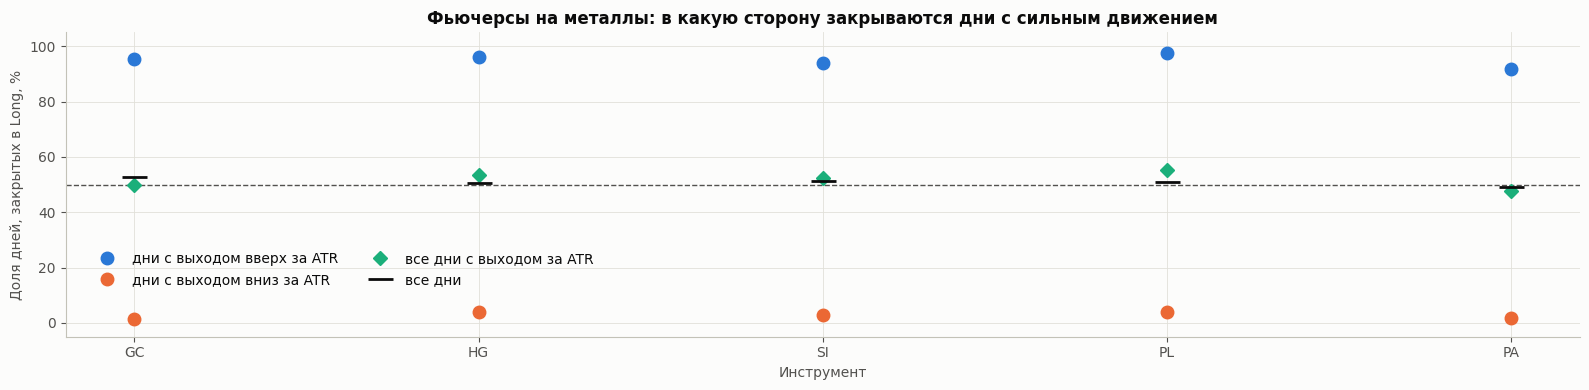


Порог ATR 30: количество дней в году, когда цена ушла от открытия дальше порога (2026 — январь–сентябрь), и направление закрытия


,2022,2023,2024,2025,2026,В среднем за год (2022–2025),"Доля дней, %",Long,Short,"Доля Long, %","Доля Long при выходе вверх, %","Доля Long при выходе вниз, %"
GC,60,58,74,70,42,65.50,25.50,151,153,49.67,95.51,1.32
HG,53,54,57,63,52,56.75,23.41,149,130,53.41,96.00,3.76
SI,57,52,70,82,41,65.25,25.34,158,144,52.32,93.94,2.78
PL,63,47,58,79,34,61.75,23.57,155,126,55.16,97.42,3.88
PA,53,40,49,68,32,52.50,20.30,115,127,47.52,91.87,1.63



Порог STD 30: количество дней в году, когда цена ушла от открытия дальше порога (2026 — январь–сентябрь), и направление закрытия


,2022,2023,2024,2025,2026,В среднем за год (2022–2025),"Доля дней, %",Long,Short,"Доля Long, %","Доля Long при выходе вверх, %","Доля Long при выходе вниз, %"
GC,146,134,149,144,107,143.25,57.05,352,328,51.76,89.76,10.17
HG,163,163,133,137,92,149.00,57.72,349,339,50.73,89.29,10.06
SI,163,131,128,151,98,143.25,56.29,339,331,50.60,91.86,11.11
PL,158,145,161,149,98,153.25,59.65,364,347,51.20,92.68,8.40
PA,146,177,157,155,96,158.75,61.33,340,390,46.58,90.40,8.15



Вся группа, 2022–2026: доля дней с сильным движением и доля Long


Доля дней, %  Long  Short  Доля Long, %
threshold kind                                                    
ATR       вниз                    11.40    18    663          2.60
          в любую сторону         23.60   728    680         51.70
          вверх                   12.60   712     37         95.10
STD       вниз                    30.50   173   1641          9.50
          в любую сторону         58.40  1744   1735         50.10
          вверх                   30.20  1636    166         90.80

Доля Long среди всех дней группы: 51.0%


In [39]:
outlier_report("metals")

### Акции сектора Health Care (здравоохранение)

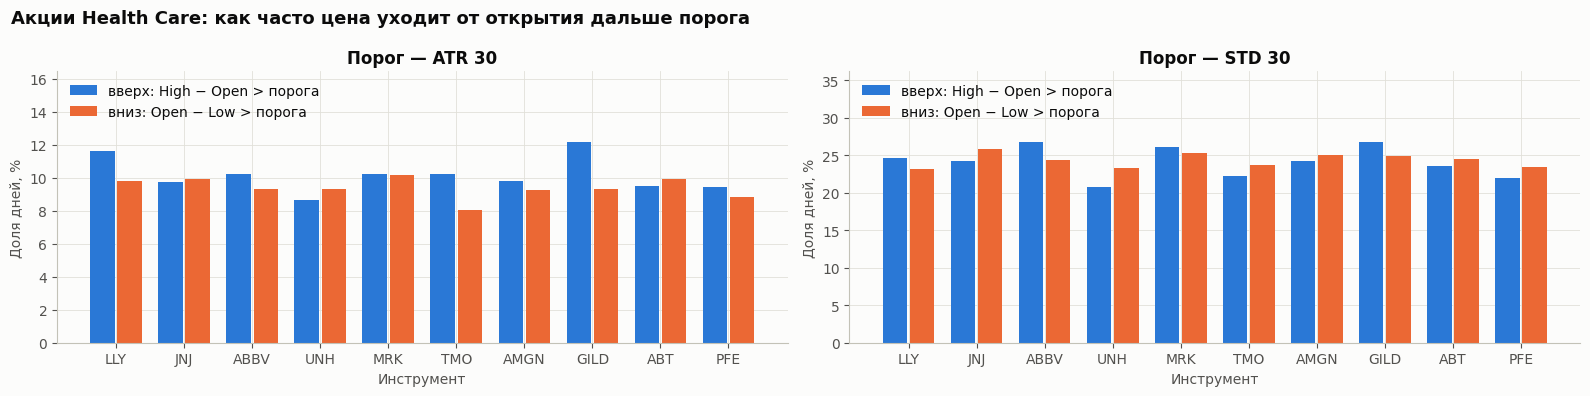

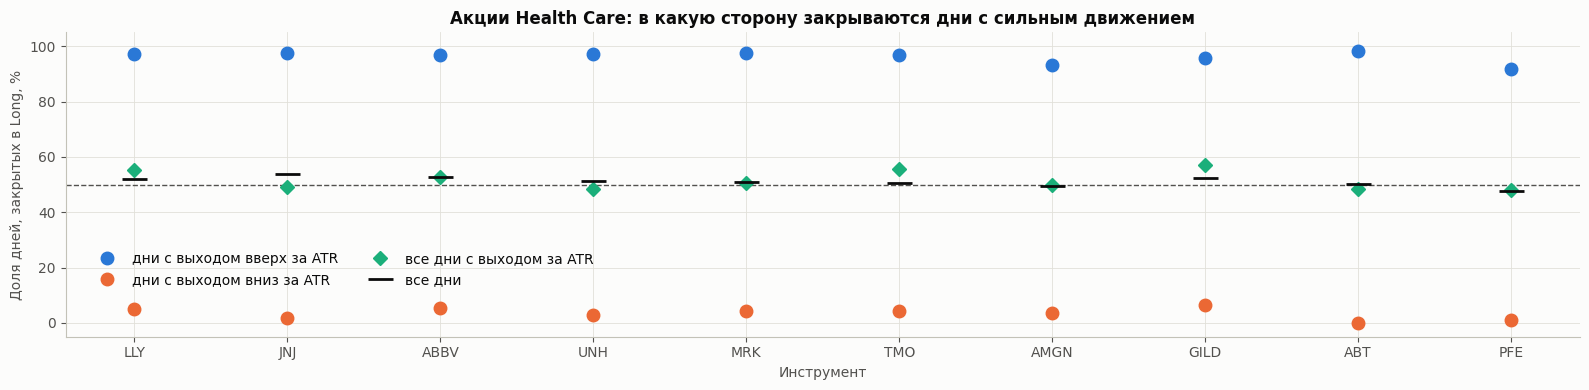


Порог ATR 30: количество дней в году, когда цена ушла от открытия дальше порога (2026 — январь–сентябрь), и направление закрытия


,2022,2023,2024,2025,2026,В среднем за год (2022–2025),"Доля дней, %",Long,Short,"Доля Long, %","Доля Long при выходе вверх, %","Доля Long при выходе вниз, %"
LLY,63,55,45,53,36,54.00,21.18,139,113,55.16,97.10,5.13
JNJ,49,45,49,50,41,48.25,19.66,115,119,49.15,97.41,1.69
ABBV,44,40,54,50,39,47.00,19.08,120,107,52.86,96.72,5.41
UNH,56,40,53,33,31,45.50,17.90,103,110,48.36,97.09,2.70
MRK,45,49,49,55,43,49.50,20.25,122,119,50.62,97.54,4.13
TMO,43,37,45,51,42,44.00,18.32,121,96,55.76,96.69,4.17
AMGN,49,51,41,44,40,46.25,18.91,112,113,49.78,93.16,3.64
GILD,52,41,60,62,41,53.75,21.51,146,110,57.03,95.86,6.31
ABT,41,46,54,54,35,48.75,19.33,111,119,48.26,98.23,0.00
PFE,36,41,49,56,34,45.50,18.15,103,112,47.91,91.89,0.95



Порог STD 30: количество дней в году, когда цена ушла от открытия дальше порога (2026 — январь–сентябрь), и направление закрытия


,2022,2023,2024,2025,2026,В среднем за год (2022–2025),"Доля дней, %",Long,Short,"Доля Long, %","Доля Long при выходе вверх, %","Доля Long при выходе вниз, %"
LLY,132,111,106,111,81,115.00,45.46,280,260,51.85,91.10,9.45
JNJ,124,106,131,118,102,119.75,48.82,292,287,50.43,93.75,10.13
ABBV,143,114,125,114,90,124.00,49.24,319,267,54.44,93.40,13.10
UNH,137,106,99,82,85,106.00,42.77,247,262,48.53,90.28,12.27
MRK,148,133,115,100,96,124.00,49.75,297,295,50.17,90.03,8.97
TMO,97,109,134,104,86,111.00,44.54,257,272,48.58,92.42,8.51
AMGN,141,126,106,106,88,119.75,47.65,276,290,48.76,89.93,8.75
GILD,122,129,112,134,101,124.25,50.25,309,289,51.67,90.28,8.75
ABT,102,116,136,124,78,119.50,46.72,276,280,49.64,90.39,9.62
PFE,123,110,106,99,89,109.50,44.29,243,283,46.20,89.66,5.02



Вся группа, 2022–2026: доля дней с сильным движением и доля Long


Доля дней, %  Long  Short  Доля Long, %
threshold kind                                                    
ATR       вниз                     9.40    38   1080          3.40
          в любую сторону         19.40  1192   1118         51.60
          вверх                   10.20  1162     46         96.20
STD       вниз                    24.30   274   2621          9.50
          в любую сторону         46.90  2796   2785         50.10
          вверх                   24.10  2615    254         91.10

Доля Long среди всех дней группы: 51.1%


In [40]:
outlier_report("health_care")

### Акции сектора Materials (сырьё и материалы)

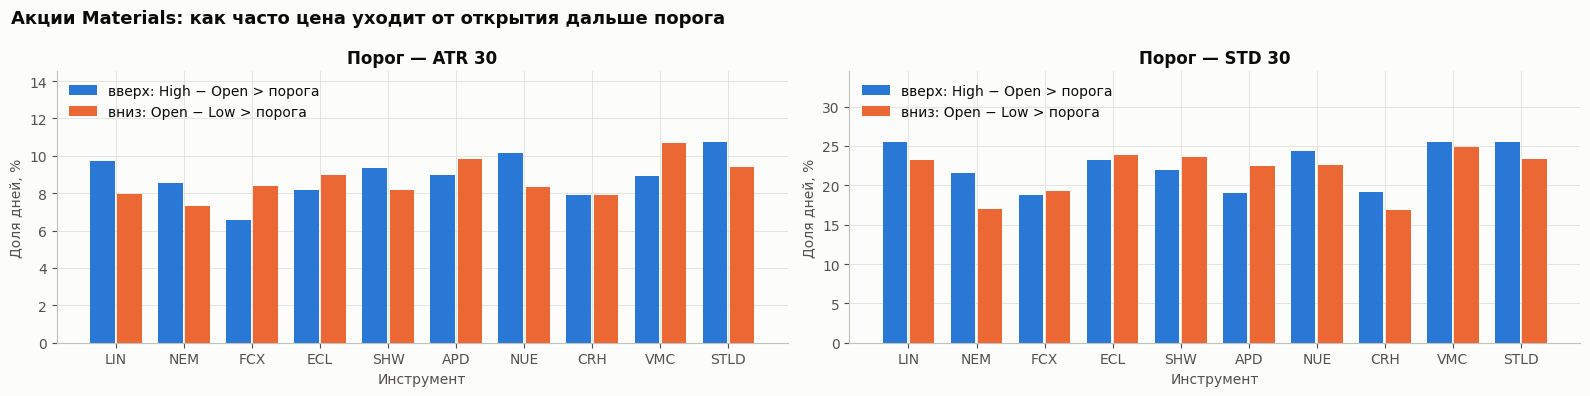

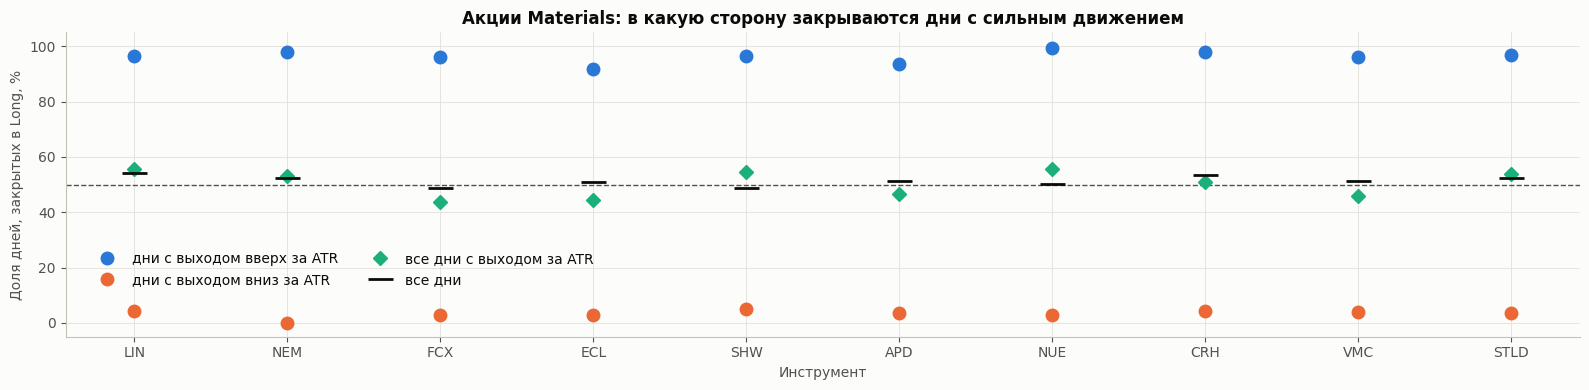


Порог ATR 30: количество дней в году, когда цена ушла от открытия дальше порога (2026 — январь–сентябрь), и направление закрытия


,2022,2023,2024,2025,2026,В среднем за год (2022–2025),"Доля дней, %",Long,Short,"Доля Long, %","Доля Long при выходе вверх, %","Доля Long при выходе вниз, %"
LIN,46,34,43,46,41,42.25,17.65,116,93,55.50,96.55,4.26
NEM,47,35,27,57,23,41.50,15.88,100,89,52.91,98.04,0.00
FCX,41,29,33,46,29,37.25,14.96,78,100,43.82,96.15,3.00
ECL,39,36,47,50,30,43.00,16.97,90,112,44.55,91.75,2.80
SHW,37,45,48,44,30,43.50,17.14,111,93,54.41,96.40,5.15
APD,47,39,44,51,38,45.25,18.40,102,117,46.58,93.46,3.42
NUE,38,39,53,45,43,43.75,18.32,121,97,55.50,99.17,3.03
CRH,22,34,54,49,27,39.75,15.63,95,91,51.08,97.87,4.26
VMC,42,40,55,54,40,47.75,19.41,106,125,45.89,96.23,3.94
STLD,54,45,47,53,39,49.75,20.00,128,110,53.78,96.88,3.57



Порог STD 30: количество дней в году, когда цена ушла от открытия дальше порога (2026 — январь–сентябрь), и направление закрытия


,2022,2023,2024,2025,2026,В среднем за год (2022–2025),"Доля дней, %",Long,Short,"Доля Long, %","Доля Long при выходе вверх, %","Доля Long при выходе вниз, %"
LIN,78,113,126,133,108,112.50,46.89,305,252,54.76,91.12,14.49
NEM,105,92,82,114,58,98.25,37.90,250,201,55.43,94.55,5.45
FCX,92,97,91,99,69,94.75,37.65,226,222,50.45,92.86,8.70
ECL,94,124,116,103,108,109.25,45.80,263,282,48.26,90.61,7.39
SHW,105,120,117,98,84,110.00,44.03,263,261,50.19,93.49,9.96
APD,104,92,89,97,90,95.50,39.66,228,244,48.31,92.95,11.61
NUE,121,117,102,108,94,112.00,45.55,284,258,52.40,93.45,8.92
CRH,55,82,104,111,71,88.00,35.55,221,201,52.37,92.95,6.47
VMC,120,115,126,121,94,120.50,48.40,295,281,51.22,92.74,9.46
STLD,127,117,118,116,84,119.50,47.23,299,263,53.20,91.78,10.79



Вся группа, 2022–2026: доля дней с сильным движением и доля Long


Доля дней, %  Long  Short  Доля Long, %
threshold kind                                                    
ATR       вниз                     8.70    35    999          3.40
          в любую сторону         17.40  1047   1027         50.50
          вверх                    8.90  1021     39         96.30
STD       вниз                    21.70   246   2338          9.50
          в любую сторону         42.90  2634   2465         51.70
          вверх                   22.50  2476    198         92.60

Доля Long среди всех дней группы: 51.3%


In [41]:
outlier_report("materials")

### Голубые фишки

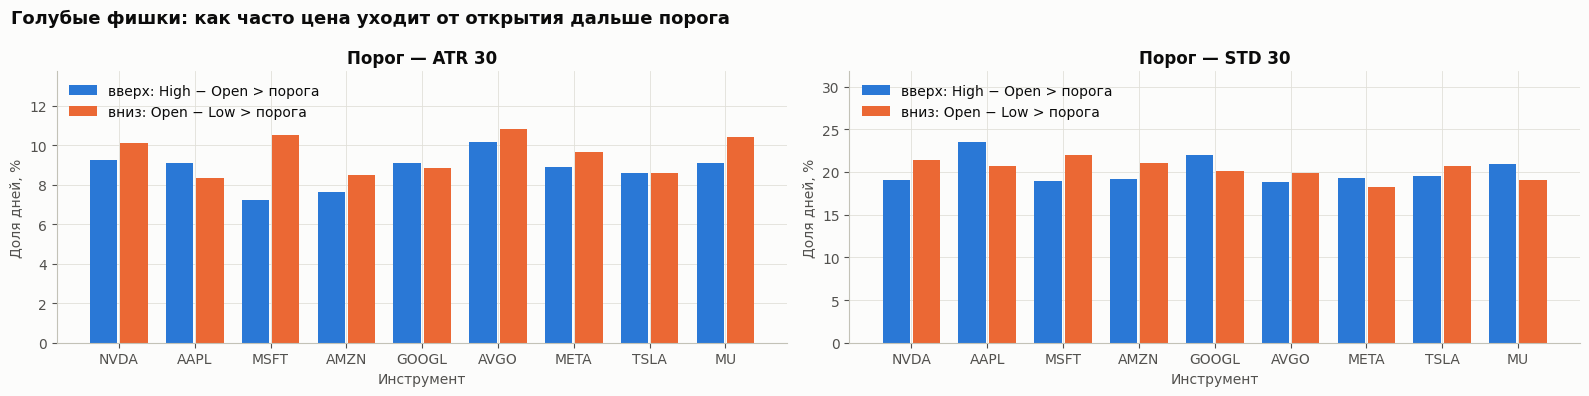

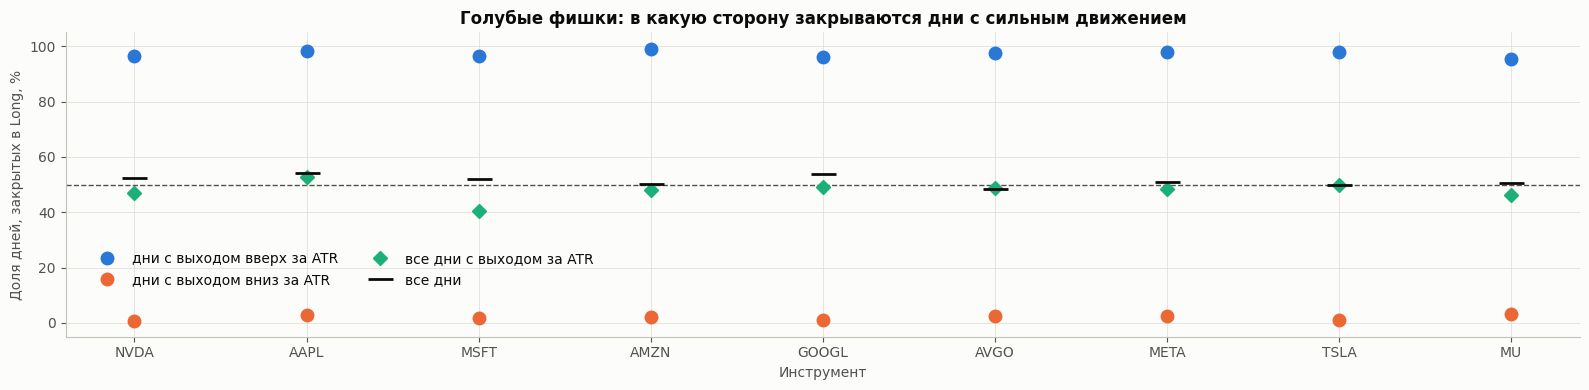


Порог ATR 30: количество дней в году, когда цена ушла от открытия дальше порога (2026 — январь–сентябрь), и направление закрытия


,2022,2023,2024,2025,2026,В среднем за год (2022–2025),"Доля дней, %",Long,Short,"Доля Long, %","Доля Long при выходе вверх, %","Доля Long при выходе вниз, %"
NVDA,29,55,67,42,35,48.25,19.16,107,121,46.93,96.36,0.83
AAPL,45,29,40,51,41,41.25,17.31,109,97,52.91,98.15,3.03
MSFT,38,36,51,45,40,42.50,17.65,85,125,40.48,96.51,1.60
AMZN,32,37,49,40,34,39.50,16.13,92,100,47.92,98.90,1.98
GOOGL,40,41,45,50,36,44.00,17.82,104,108,49.06,96.30,0.95
AVGO,45,60,67,46,31,54.50,20.92,121,128,48.59,97.52,2.33
META,31,54,48,47,41,45.00,18.57,107,114,48.42,98.11,2.61
TSLA,40,39,53,44,27,44.00,17.06,101,102,49.75,98.04,0.98
MU,39,43,47,51,52,45.00,19.50,107,125,46.12,95.37,3.23



Порог STD 30: количество дней в году, когда цена ушла от открытия дальше порога (2026 — январь–сентябрь), и направление закрытия


,2022,2023,2024,2025,2026,В среднем за год (2022–2025),"Доля дней, %",Long,Short,"Доля Long, %","Доля Long при выходе вверх, %","Доля Long при выходе вниз, %"
NVDA,89,104,112,95,73,100.00,39.75,227,246,47.99,95.15,5.51
AAPL,93,110,103,99,98,101.25,42.27,273,230,54.27,91.07,10.98
MSFT,90,90,121,105,71,101.50,40.08,219,258,45.91,94.22,4.60
AMZN,85,108,108,84,85,96.25,39.50,225,245,47.87,92.98,6.77
GOOGL,91,104,108,108,80,102.75,41.26,251,240,51.12,91.60,6.25
AVGO,93,112,94,93,65,98.00,38.40,225,232,49.23,95.98,4.66
META,68,108,105,98,57,94.75,36.64,225,211,51.61,93.89,7.37
TSLA,117,93,84,99,78,98.25,39.58,224,247,47.56,93.13,3.25
MU,104,101,85,106,72,99.00,39.33,236,232,50.43,90.76,5.73



Вся группа, 2022–2026: доля дней с сильным движением и доля Long


Доля дней, %  Long  Short  Доля Long, %
threshold kind                                                    
ATR       вниз                     9.50    20   1000          2.00
          в любую сторону         18.20   933   1020         47.80
          вверх                    8.80   914     26         97.20
STD       вниз                    20.30   133   2045          6.10
          в любую сторону         39.60  2105   2141         49.60
          вверх                   20.10  2008    149         93.10

Доля Long среди всех дней группы: 51.4%


In [42]:
outlier_report("blue_chips")

### Сравнение групп по годам

Доля Long среди дней с сильным движением (в любую сторону) по годам — чтобы увидеть, как баланс направлений зависит от рыночного режима.

In [43]:
yr = ev[ev["kind"] == "max"].groupby(["threshold", "group", "year"])[["events", "long", "short", "days"]].sum()
yr["long_share"] = yr["long"] / (yr["long"] + yr["short"]) * 100
yr["freq"] = yr["events"] / yr["days"] * 100
for thr in ["ATR", "STD"]:
    t = yr.loc[thr]
    out = pd.concat({"Доля дней с выходом, %": t["freq"].unstack(), "Доля Long, %": t["long_share"].unstack()}, axis=1)
    out.index = [GROUP_NAME[g] for g in out.index]
    out = out.loc[[GROUP_NAME[g] for g in GROUP_IDS]]
    out.columns = pd.MultiIndex.from_tuples([(a, str(b)) for a, b in out.columns])
    print(f"\nПорог {thr} 30")
    display(out.round(1))


Порог ATR 30


Доля дней с выходом, %                         Доля Long, %                        
                                      2022  2023  2024  2025  2026         2022  2023  2024  2025  2026
Фьючерсы на индексы                  20.80 20.60 26.70 22.90 24.60        41.00 52.90 48.10 43.40 51.50
Фьючерсы на металлы                  22.80 20.10 24.40 28.70 21.50        46.20 51.80 52.60 58.00 46.80
Акции Health Care                    19.00 17.80 19.80 20.30 20.40        52.70 47.60 47.50 54.30 56.50
Акции Materials                      16.50 15.00 17.90 19.80 18.20        48.40 56.10 48.00 49.30 51.80
Голубые фишки                        15.00 17.50 20.60 18.50 20.00        44.20 57.40 43.90 41.10 53.70


Порог STD 30


Доля дней с выходом, %                         Доля Long, %                        
                                      2022  2023  2024  2025  2026         2022  2023  2024  2025  2026
Фьючерсы на индексы                  54.70 57.80 56.10 52.90 59.60        43.60 51.00 52.80 50.10 53.40
Фьючерсы на металлы                  61.80 60.00 57.80 58.40 52.50        47.60 47.50 50.00 58.00 46.40
Акции Health Care                    50.60 46.40 46.40 43.70 47.90        52.00 47.70 48.20 52.20 50.60
Акции Materials                      39.90 42.80 42.50 44.00 46.00        49.10 54.60 50.90 51.60 52.00
Голубые фишки                        36.70 41.30 40.60 39.40 40.30        44.80 56.50 47.10 47.60 52.00

#### Вывод по разделу 7

**Как часто бывают сильные дни (порог — ATR)**

Цена уходит от открытия дальше своего ATR примерно в каждый пятый день:

| Группа | Доля дней | Дней в год | Вверх | Вниз |
|---|---|---|---|---|
| Фьючерсы на индексы | 23.0% | 52–61 | 10.8% | 12.7% |
| Фьючерсы на металлы | 23.6% | 52–66 | 12.6% | 11.4% |
| Акции Health Care | 19.4% | 44–54 | 10.2% | 9.4% |
| Акции Materials | 17.4% | 37–50 | 8.9% | 8.7% |
| Голубые фишки | 18.2% | 40–55 | 8.8% | 9.5% |

- **У акций сильных дней меньше, чем у фьючерсов**, и причина методическая. ATR акций включает ночные разрывы между вчерашним закрытием и сегодняшним открытием, а отклонение мы меряем от цены открытия, когда разрыв уже позади. Поэтому для акций порог ATR получается «строже». Фьючерсы торгуются почти круглосуточно, разрывов у них мало.
- **У фьючерсов на индексы движения вниз за ATR случаются чаще, чем вверх** (12.7% против 10.8% дней). Это известная асимметрия фондового рынка: падения резче и быстрее ростов. У металлов, наоборот, чаще сильные движения вверх.
- **STD как порог слишком мягкий.** Его превышают 40–58% дней: STD в 1.5 раза меньше ATR, и «сильным» по нему оказывается почти каждый второй день. Если использовать STD как порог выброса, его нужно умножать хотя бы на 1.5–2.

**В какую сторону закрываются сильные дни**

- **Если цена за день ушла от открытия вверх дальше ATR, день почти всегда закрывается в Long** (92–99% случаев). Если вниз — в Short (92–100%). Отчасти это механика: чтобы закрыться по другую сторону от открытия, цене нужно пройти обратно ещё больше ATR, а это редкость. Но вывод для проекта важен: после выхода за ATR развороты за точку открытия почти не случаются.
- **По группам Long и Short среди всех сильных дней — почти поровну:** индексы 47.2% Long, металлы 51.7%, Health Care 51.6%, Materials 50.5%, голубые фишки 47.8%. Для сравнения: среди всех дней доля Long — 51–52%. У фьючерсов на индексы и голубых фишек сильные дни чаще заканчиваются падением, чем обычные.
- **Баланс зависит от состояния рынка.**
    - В 2022 году (падающий рынок) доля Long среди сильных дней у индексов — 41%, у голубых фишек — 44%.
    - В 2023 году (рост) — 53% и 57%.
    - В 2025 году металлы росли — 58% Long, а голубые фишки пережили апрельский обвал — 41% Long.
- **Отдельные инструменты заметно смещены:**
    - вниз — Microsoft (MSFT, 40.5% Long среди сильных дней), Freeport-McMoRan (FCX, 43.8%), Ecolab (ECL, 44.6%), ES (45.7%);
    - вверх — Gilead (GILD, 57.0%), Thermo Fisher (TMO, 55.8%), Linde и Nucor (LIN, NUE, 55.5%), платина (PL, 55.2%).

**Что это значит для проекта.**
- Сильные движения на 1 ATR от открытия случаются в 17–24% дней. Это ориентир для разметки целевой переменной: сколько примеров «выхода» мы получим.
- Классы Long и Short в целом сбалансированы, но баланс меняется вместе с рыночным режимом. Модели нужно проверять отдельно на разных годах, иначе модель, обученная на 2023 годе, будет систематически ошибаться в годы вроде 2022-го.
- Раз после выхода за ATR направление закрытия почти предопределено, основная ценность модели — предсказать направление **раньше**, в момент выхода цены из консолидации, пока движение ещё не произошло. Это стоит делать на внутридневных таймфреймах.

## 8. Итоговый вывод

Мы рассчитали признаки волатильности ATR и STD для 39 инструментов на всех таймфреймах и провели разведочный анализ объёмов, связей между инструментами, динамики волатильности и сильных дневных движений. Главные результаты:

1. **Волатильность нужно сравнивать в процентах от цены.** Типичный дневной ATR — от 1.2% у фьючерса на Dow Jones до 4.7% у Tesla, а у одного инструмента минимум и максимум за пять лет различаются в 2–5 раз. Любые пороги — для консолидации, для сильного движения — нужно задавать относительно собственной волатильности инструмента в текущий период.

2. **Активность рынка сильнее всего зависит от часа торгов.**
    - **Час.** В пиковые часы (открытие и закрытие фондового рынка) торгуется в несколько раз больше, чем в обед, и в 10 и более раз больше, чем ночью.
    - **День недели — эффект слабее (±5–9%).** Понедельник тихий; у акций пятница самая активная.
    - **Месяц — эффект ещё слабее (±5–20%).** Лето и (у фьючерсов на индексы) декабрь тихие, конец зимы и весна активные.
    - Разовые события — апрель 2025 года, металлы в начале 2026 года — влияют сильнее любого календаря.

3. **Группы инструментов заметно различаются.**
    - **Фьючерсы на индексы** почти не отличаются друг от друга (корреляция до 0.95), торгуются в часы фондового рынка, чаще резко падают, чем резко растут.
    - **Металлы** живут своей жизнью: слабо связаны с фондовым рынком, активны в утренние часы, почти без недельной сезонности, пережили сильнейший всплеск волатильности в начале 2026 года.
    - **Health Care** — самая спокойная и «ровная» группа акций.
    - **Materials** — самая выраженная сезонность (активный март, тихий август), сильная связь внутри отраслей.
    - **Голубые фишки** — самые волатильные, сильнее всего связаны с индексами и активнее всех торгуются вне основной сессии.

4. **ATR и STD описывают одно явление, но по-разному.** ATR в 1.2–1.7 раза больше, меняется плавно и учитывает внутридневной размах. STD резко реагирует на отдельные шоковые дни. Для индикатора консолидации основой лучше сделать ATR.

5. **Сильные движения (больше ATR от цены открытия) случаются в 17–24% дней.**
    - Направления Long и Short среди них почти сбалансированы, но баланс зависит от рыночного режима.
    - После выхода за ATR день почти всегда закрывается в сторону выхода. Значит, ценность модели — предсказать направление до того, как движение произошло.

**Рекомендации для следующих этапов проекта**
- Строить индикатор консолидации на нормированной волатильности: ATR в процентах, отношение ATR короткого и длинного периодов, ширина диапазона за N баров относительно ATR.
- Добавить в модели признаки времени (час, день недели) и относительного объёма — объёма бара по сравнению с типичным объёмом этого же часа.
- Для акций рассмотреть вариант ATR без ночных разрывов — по диапазону основной сессии: для внутридневного анализа он точнее.
- Проверять модели строго по времени (обучение на прошлом, проверка на будущем), отдельно по разным годам и рыночным режимам; учитывать, что фьючерсы на индексы почти не дают независимых примеров.
- Если использовать STD как порог сильного движения — брать его с множителем 1.5–2.

Резюме: EDA анализ рыночных характеристик в лице волатильности и изменения цены (ATR n STD) позволил выявить важные детали для дальнейших этапов. Опишем детальнее.

- - для кастомного индикатора консолидаций - стало ясно, что имеет смысл анализировать консолидации в преддверии самых активных часов на рынке, ровно как и учесть сезонность (от глобального) по месяцам, так и активность внутри недели по дням (к локальному)
- - для классификатора - стало ясно, что лишь индексы можно рассматривать как "единый" актив в силу сильной корреляции и дабы избежать переобучения, обучать модель на одном индексе СП500; остальные рынки именно этот пункт не касается. Но есть и еще один важный нюанс, что даже внутри группы отдельные фьючерсы и компании ведут себя по-разному и проектировать модель под группу очень опрометчиво, тогда как проектировать модель под каждый инструмент может быть накладно по времени - всё равно это видится единственным верным направлением

Следующим этапом исследования будет выявление ансамбля характеристик волатильности для проектирования кастомного индикатора консолидаций.

**Источники**
- J. Welles Wilder Jr. *New Concepts in Technical Trading Systems*, 1978 — исходное определение True Range и ATR.
- [Average true range — Wikipedia](https://en.wikipedia.org/wiki/Average_true_range)
- [ATR Calculation Methods — Macroption](https://www.macroption.com/atr-calculation/) — способы сглаживания ATR.
- [Average True Range — StockCharts ChartSchool](https://chartschool.stockcharts.com/table-of-contents/technical-indicators-and-overlays/technical-indicators/average-true-range-atr-and-average-true-range-percent-atrp) — ATR и ATR в процентах.
- Данные: Massive (бары фьючерсов CME/CBOT/COMEX/NYMEX и акций), состав секторов S&P 500 — фонды State Street Select Sector SPDR.